# **Context**

There is an infinite number of objects in outer space. Some of them are closer than we might think. Although it might seem that a distance of 70,000 km cannot potentially harm us, on an astronomical scale, it is a very small distance that can disrupt many natural phenomena. These objects/asteroids may therefore prove to be harmful. That is why it is worth knowing what surrounds us and what could harm us. This dataset contains a list of NASA-certified asteroids that are classified as near-Earth objects.

**Sources**
- NASA Open API
- NEO Earth Close Approaches

Based on the existing dataset, we need to build a model that will allow us to determine which celestial bodies pose a threat to Earth.

💥 What is the nature of this danger?

- The threat itself is directly dependent on the size of the celestial body. While small objects (up to 20 meters, like the Chelyabinsk meteorite) cause only a local shockwave and shatter windows, large bodies bring catastrophic consequences:

- Destruction of cities (size from 140 meters) – The impact of such an asteroid on land is capable of completely destroying a large metropolis or a small country, leaving behind a huge crater.

- Global tsunami (size from 140 meters) – An impact into the ocean (which is statistically more likely) will trigger massive waves. They will wash away coastal cities within a radius of thousands of kilometers.

- Climate collapse (size from 1 km) – The explosion will lift millions of tons of dust, ash, and sulfur into the atmosphere. They will block sunlight for long months or years. An "asteroid winter" will set in, destroying agriculture and causing mass famine.

- Mass extinction (size from 10 km) – Exactly such an object fell 66 million years ago and led to the extinction of the dinosaurs. Complete destruction of the planet's ecosystems will occur.

In [1]:
# Python 3.13.1 environment

# Loading required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score, recall_score, f1_score, precision_recall_curve
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier, Pool
import xgboost as xgb
import lightgbm as lgb
import time
import pickle
import joblib
import os

# warnings remobing
import warnings
warnings.filterwarnings('ignore')

## **1. Data Exploration**

In [2]:
# Dataset Loading

df = pd.read_csv('data/neo.csv')
df

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True
...,...,...,...,...,...,...,...,...,...,...
90831,3763337,(2016 VX1),0.026580,0.059435,52078.886692,1.230039e+07,Earth,False,25.00,False
90832,3837603,(2019 AD3),0.016771,0.037501,46114.605073,5.432121e+07,Earth,False,26.00,False
90833,54017201,(2020 JP3),0.031956,0.071456,7566.807732,2.840077e+07,Earth,False,24.60,False
90834,54115824,(2021 CN5),0.007321,0.016370,69199.154484,6.869206e+07,Earth,False,27.80,False


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  str    
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  str    
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), str(2)
memory usage: 5.7 MB


**Dataset Column Descriptions:**

**id** - Unique identifier for each object

**name** - NASA-assigned name

**est_diameter_min** - Minimum estimated diameter in kilometers

**est_diameter_max** - Maximum estimated diameter in kilometers

**relative_velocity** - Velocity relative to Earth in km/h

**miss_distance** - Missed distance in kilometers

**orbiting_body** - Planet around which the asteroid orbits

**sentry_object** - Included with Sentry - an automated collision monitoring system

**absolute_magnitude** - Describes the intrinsic magnitude

________________________________________________________________________________________________________________________________

**hazardous** - A Boolean function indicating whether the asteroid is hazardous or not - We need to predict in this cell whether the object is hazardous to Earth or not.

## 1.1 Basic data analysis

In [3]:
# Basic information
print("=== Basic Information ===")
print(f"Dataset size: {df.shape}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nStatistics:\n{df.describe()}")

# Check for missing values
print(f"\nMissing values:\n{df.isnull().sum()}")

# Check the balance of classes
print(f"\nDistribution of the target variable 'hazardous':")
print(df['hazardous'].value_counts())
print(f"\nPercentage of hazardous asteroids: {df['hazardous'].mean():.2%}")

=== Basic Information ===
Dataset size: (90836, 10)

Data types:
id                      int64
name                   object
est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
orbiting_body          object
sentry_object            bool
absolute_magnitude    float64
hazardous                bool
dtype: object

Statistics:
                 id  est_diameter_min  est_diameter_max  relative_velocity  \
count  9.083600e+04      90836.000000      90836.000000       90836.000000   
mean   1.438288e+07          0.127432          0.284947       48066.918918   
std    2.087202e+07          0.298511          0.667491       25293.296961   
min    2.000433e+06          0.000609          0.001362         203.346433   
25%    3.448110e+06          0.019256          0.043057       28619.020645   
50%    3.748362e+06          0.048368          0.108153       44190.117890   
75%    3.884023e+06          0.143402          0.320656       

**Conclusion:**

- The dataset contains 90,836 records

- No gaps (all columns are 100% filled)

- Strong class imbalance (9.73% hazardous asteroids)

In [ ]:
# Unique values ​​of the 'sentry_object' feature
df['sentry_object'].unique()

array([False])

In [ ]:
# Unique values ​​of the 'orbiting_body' feature
df['orbiting_body'].unique()

array(['Earth'], dtype=object)

We see that the features "sentry_object" and "orbiting_body" are constant. The features "id" and "name" do not provide useful information for making predictions. These three features can be removed from our dataset.

In [3]:
df = df.drop(['id', 'name', 'sentry_object', 'orbiting_body'], axis=1)

In [4]:
df

,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,1.198271,2.679415,13569.249224,5.483974e+07,16.73,False
1,0.265800,0.594347,73588.726663,6.143813e+07,20.00,True
2,0.722030,1.614507,114258.692129,4.979872e+07,17.83,False
3,0.096506,0.215794,24764.303138,2.543497e+07,22.20,False
4,0.255009,0.570217,42737.733765,4.627557e+07,20.09,True
...,...,...,...,...,...,...
90831,0.026580,0.059435,52078.886692,1.230039e+07,25.00,False
90832,0.016771,0.037501,46114.605073,5.432121e+07,26.00,False
90833,0.031956,0.071456,7566.807732,2.840077e+07,24.60,False
90834,0.007321,0.016370,69199.154484,6.869206e+07,27.80,False


## 1.2 Distribution visualization

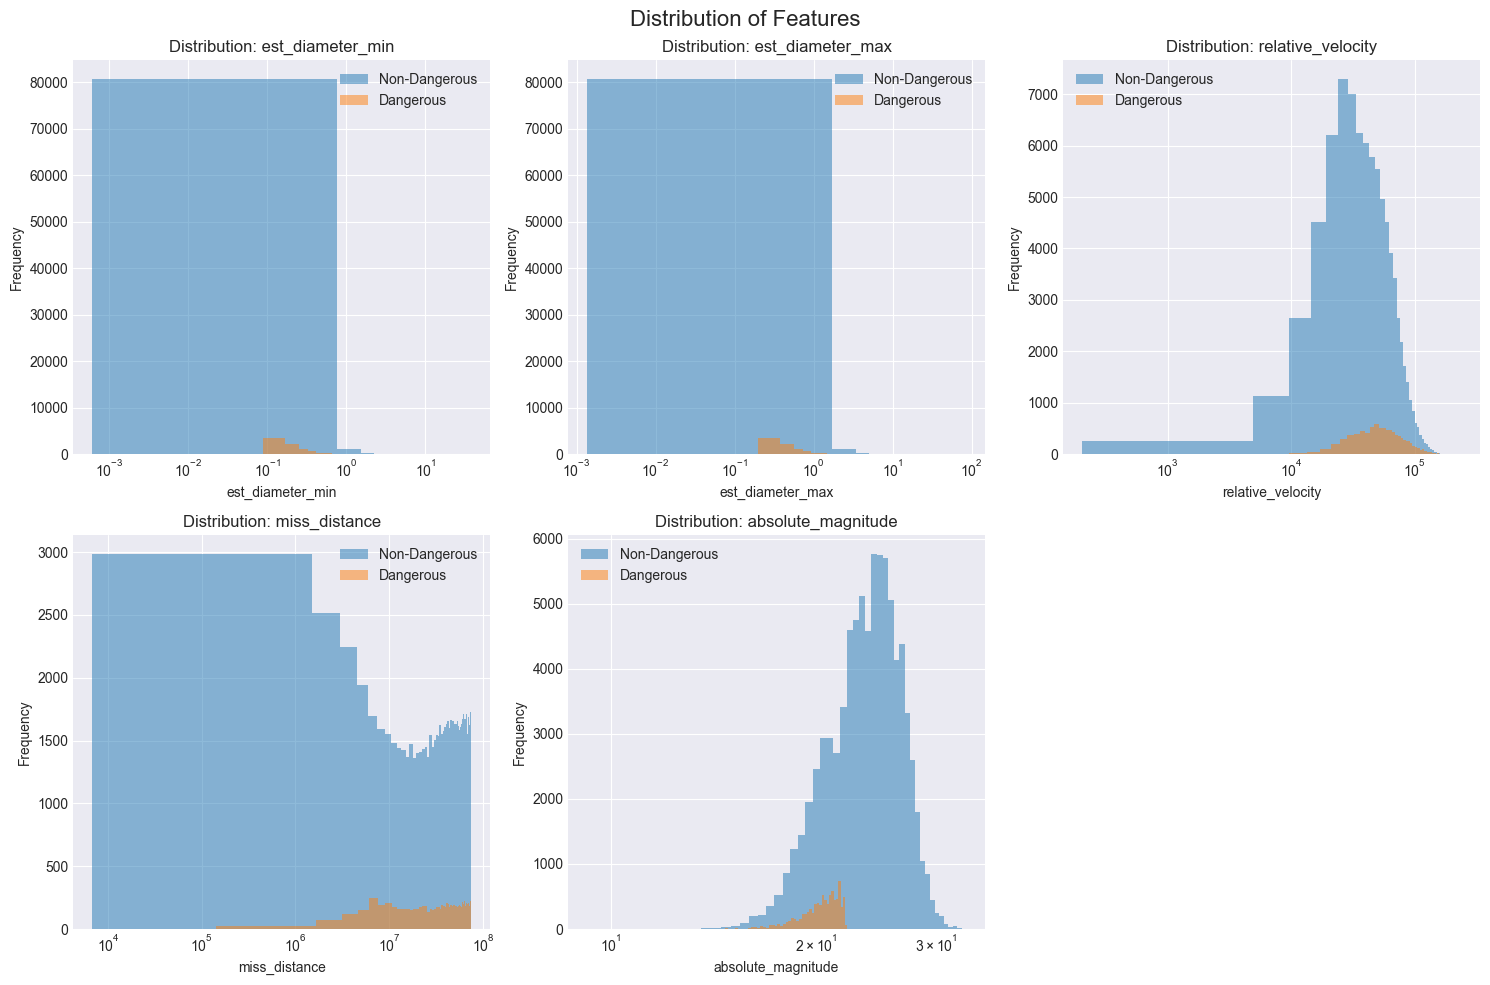

In [6]:
# Style setting
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distribution of Features', fontsize=16)

# Histograms for numeric features
numeric_cols = ['est_diameter_min', 'est_diameter_max', 'relative_velocity', 
                'miss_distance', 'absolute_magnitude']

for idx, col in enumerate(numeric_cols):
    row, col_idx = idx // 3, idx % 3
    ax = axes[row, col_idx]
    
    # Chapter by class
    for hazardous in [0, 1]:
        subset = df[df['hazardous'] == hazardous][col]
        ax.hist(subset, bins=50, alpha=0.5, label=f'{"Dangerous" if hazardous else "Non-Dangerous"}')
    
    ax.set_title(f'Distribution: {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.set_xscale('log')  # Logarithmic scale for better visualization

# Hide the last (empty) subplot
axes[1, 2].set_visible(False)

plt.tight_layout()
plt.show()

## 1.3 Correlation analysis

Data types in the dataset:
est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
absolute_magnitude    float64
hazardous                bool
dtype: object

Columns in numeric_df: ['est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'absolute_magnitude', 'hazardous']
Data types in numeric_df:
est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
absolute_magnitude    float64
hazardous               int64
dtype: object


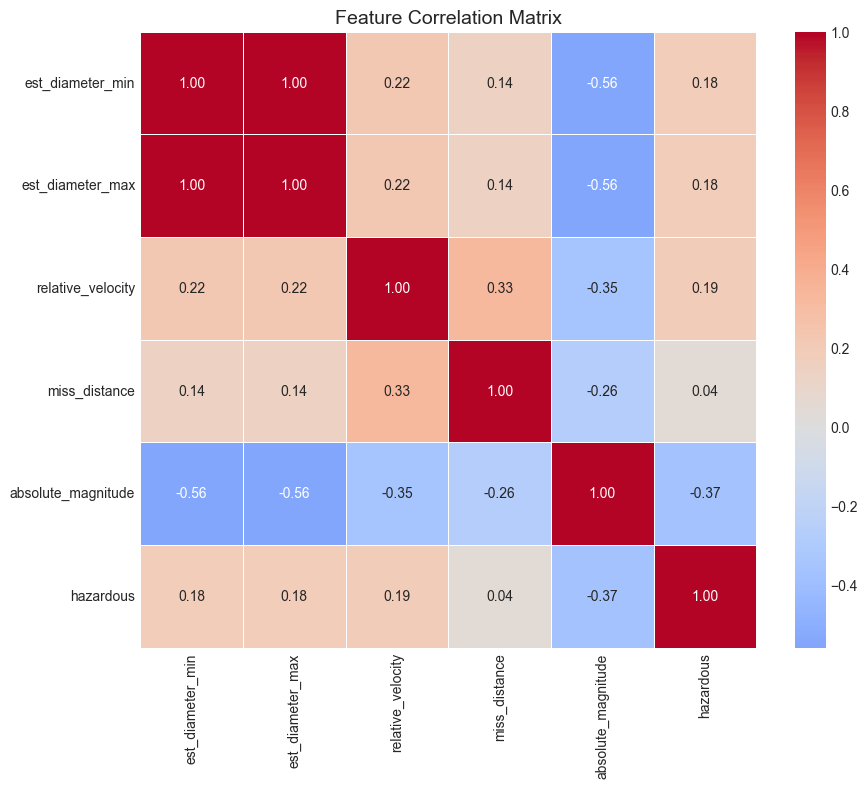


=== CORRELATION WITH THE TARGET VARIABLE ===
hazardous             1.000000
relative_velocity     0.191185
est_diameter_max      0.183363
est_diameter_min      0.183363
miss_distance         0.042302
absolute_magnitude   -0.365267
Name: hazardous, dtype: float64


In [7]:
# Check data types
print("Data types in the dataset:")
print(df.dtypes)
print("\n" + "="*50)

# Create a copy for numerical analysis
numeric_df = df.select_dtypes(include=[np.number, bool]).copy()

# Convert all boolean columns to int
bool_cols = numeric_df.select_dtypes(include=[bool]).columns
for col in bool_cols:
    numeric_df[col] = numeric_df[col].astype(int)

print(f"Columns in numeric_df: {numeric_df.columns.tolist()}")
print(f"Data types in numeric_df:\n{numeric_df.dtypes}")

# Correlation matrix
plt.figure(figsize=(10, 8))
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix', fontsize=14)
plt.show()

# Correlation with the target variable
print("\n=== CORRELATION WITH THE TARGET VARIABLE ===")
# Check if 'hazardous' is in the dataframe
if 'hazardous' in numeric_df.columns:
    corr_with_target = numeric_df.corr()['hazardous'].sort_values(ascending=False)
    print(corr_with_target)
else:
    print("Column 'hazardous' was not found in numeric_df")
    print(f"Available columns: {numeric_df.columns.tolist()}")

**Key Observations:**

1. MOST IMPORTANT FEATURE: absolute_magnitude (-0.3653)
- Negative correlation: the lower the absolute_magnitude (the brighter the object),
the greater the probability of a threat.
- This is the strongest predictor in the dataset.

2. SECOND MOST IMPORTANT FEATURE: relative_velocity (0.1912)
- Positive correlation: the higher the velocity, the greater the risk.
- Moderate but significant correlation.

3. DIAMETER (est_diameter_min/max): ~0.1834
- Positive correlation: larger asteroids are more dangerous.
- Two features are almost identical (multicollinearity!)
- Only one should be retained.

4. WEAKEST RELATIONSHIP: miss_distance (0.0423)
- Very weak positive correlation.
- Contrary to expectations, this is not a strong predictor.
- It is possible that all asteroids in the dataset are already classified as NEOs.

## 1.4 Box-plot analysis

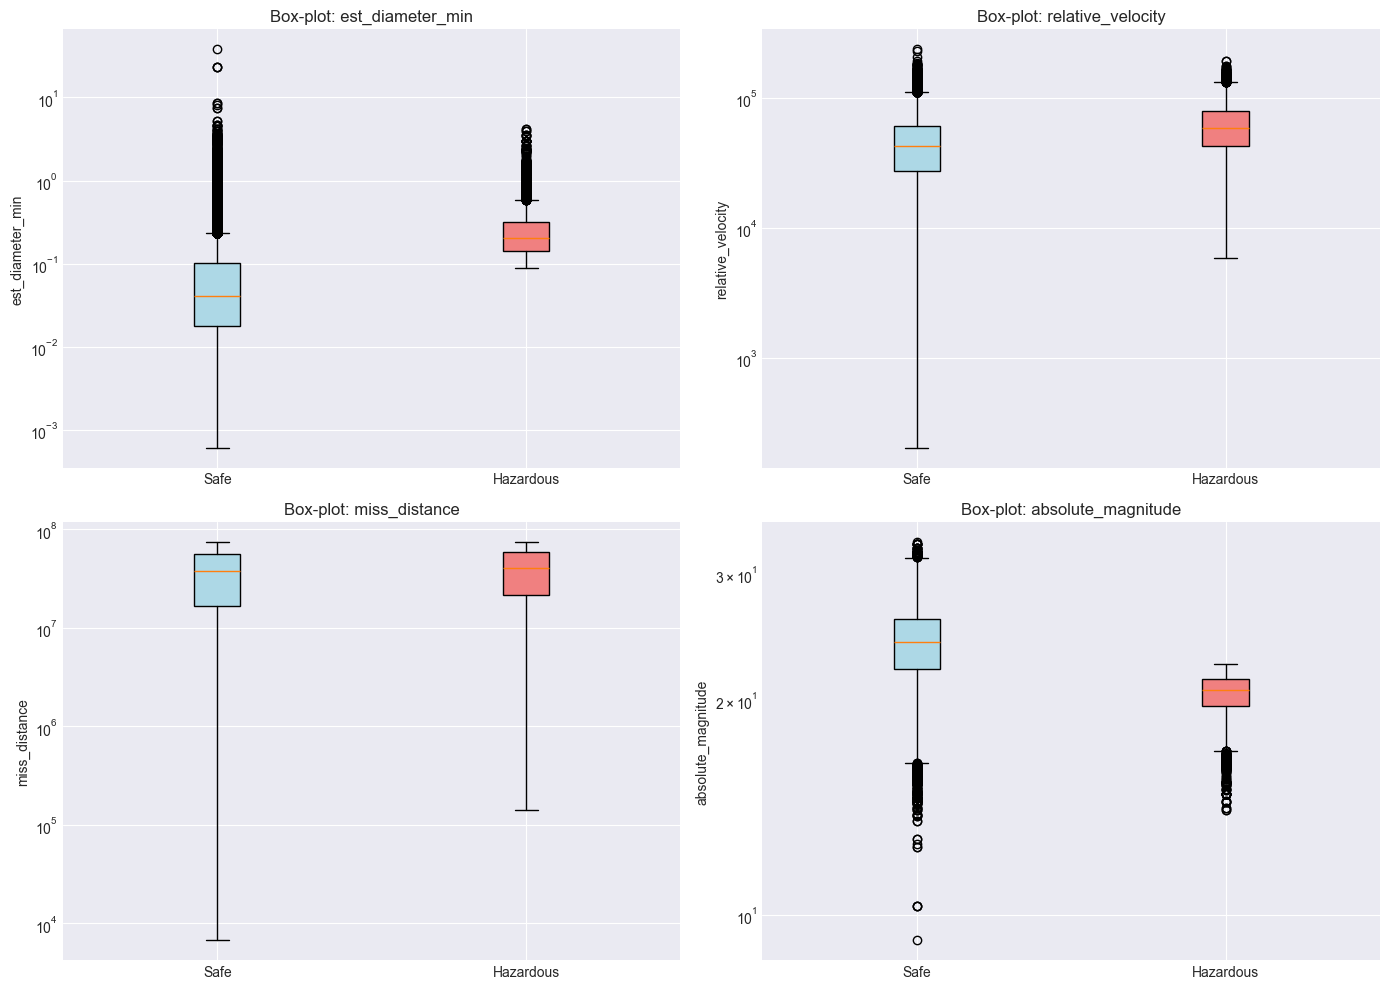

In [8]:
# Box-plot to compare distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features_for_box = ['est_diameter_min', 'relative_velocity', 'miss_distance', 'absolute_magnitude']

for idx, feature in enumerate(features_for_box):
    row, col = idx // 2, idx % 2
    ax = axes[row, col]
    
    data_to_plot = [df[df['hazardous'] == 0][feature].values,
                    df[df['hazardous'] == 1][feature].values]
    
    bp = ax.boxplot(data_to_plot, labels=['Safe', 'Hazardous'], patch_artist=True)
    bp['boxes'][0].set_facecolor('lightblue')
    bp['boxes'][1].set_facecolor('lightcoral')
    
    ax.set_title(f'Box-plot: {feature}')
    ax.set_ylabel(feature)
    ax.set_yscale('log')  # Logarithmic scale

plt.tight_layout()
plt.show()

**Conclusion:**

We see that "dangerous" objects differ from "non-dangerous" objects by:
- larger diameter,
- slightly higher speed,
- slightly greater distance traveled in kilometers,
- lower internal luminescence.

## **2. Preparing data for modeling**

## 2.1 We create new features to improve the model

In [5]:
# Create a copy of the dataset
df_clean = df.copy()

# 1. Average diameter
df_clean['avg_diameter'] = (df_clean['est_diameter_min'] + df_clean['est_diameter_max']) / 2
df_clean = df_clean.drop(['est_diameter_min', 'est_diameter_max'], axis=1)

# 2. Kinetic energy (for a better distribution)
df_clean['kinetic_energy'] = df_clean['avg_diameter'] ** 3 * df_clean['relative_velocity'] ** 2

# 3. Velocity to distance ratio
df_clean['velocity_distance_ratio'] = df_clean['relative_velocity'] / (df_clean['miss_distance'] + 1)

print("✅ New features created:")
print("  - kinetic_energy: kinetic energy (mass * velocity²)")
print("  - velocity_distance_ratio: ratio of velocity to distance")

# Select the final set of features
selected_features = [
    'absolute_magnitude',      # Most important feature
    'relative_velocity',       # Second most important
    'avg_diameter',            # Instead of two correlated features
    'miss_distance',           # Kept for completeness
    'kinetic_energy',          # New feature
    'velocity_distance_ratio'  # New feature
]

print(f"\nFinal feature set ({len(selected_features)} features):")
for i, feat in enumerate(selected_features, 1):
    # Check data type
    dtype = df_clean[feat].dtype
    nunique = df_clean[feat].nunique()
    print(f"  {i}. {feat} ({dtype}) - unique values: {nunique}")

✅ New features created:
  - kinetic_energy: kinetic energy (mass * velocity²)
  - velocity_distance_ratio: ratio of velocity to distance

Final feature set (6 features):
  1. absolute_magnitude (float64) - unique values: 1638
  2. relative_velocity (float64) - unique values: 90828
  3. avg_diameter (float64) - unique values: 1638
  4. miss_distance (float64) - unique values: 90536
  5. kinetic_energy (float64) - unique values: 90829
  6. velocity_distance_ratio (float64) - unique values: 90828


In [6]:
df_clean

,relative_velocity,miss_distance,absolute_magnitude,hazardous,avg_diameter,kinetic_energy,velocity_distance_ratio
0,13569.249224,5.483974e+07,16.73,False,1.938843,1.341960e+09,0.000247
1,73588.726663,6.143813e+07,20.00,True,0.430073,4.307749e+08,0.001198
2,114258.692129,4.979872e+07,17.83,False,1.168268,2.081643e+10,0.002294
3,24764.303138,2.543497e+07,22.20,False,0.156150,2.334963e+06,0.000974
4,42737.733765,4.627557e+07,20.09,True,0.412613,1.283071e+08,0.000924
...,...,...,...,...,...,...,...
90831,52078.886692,1.230039e+07,25.00,False,0.043007,2.157502e+05,0.004234
90832,46114.605073,5.432121e+07,26.00,False,0.027136,4.249177e+04,0.000849
90833,7566.807732,2.840077e+07,24.60,False,0.051706,7.915042e+03,0.000266
90834,69199.154484,6.869206e+07,27.80,False,0.011845,7.958467e+03,0.001007


## 2.2 Checking correlation between selected features

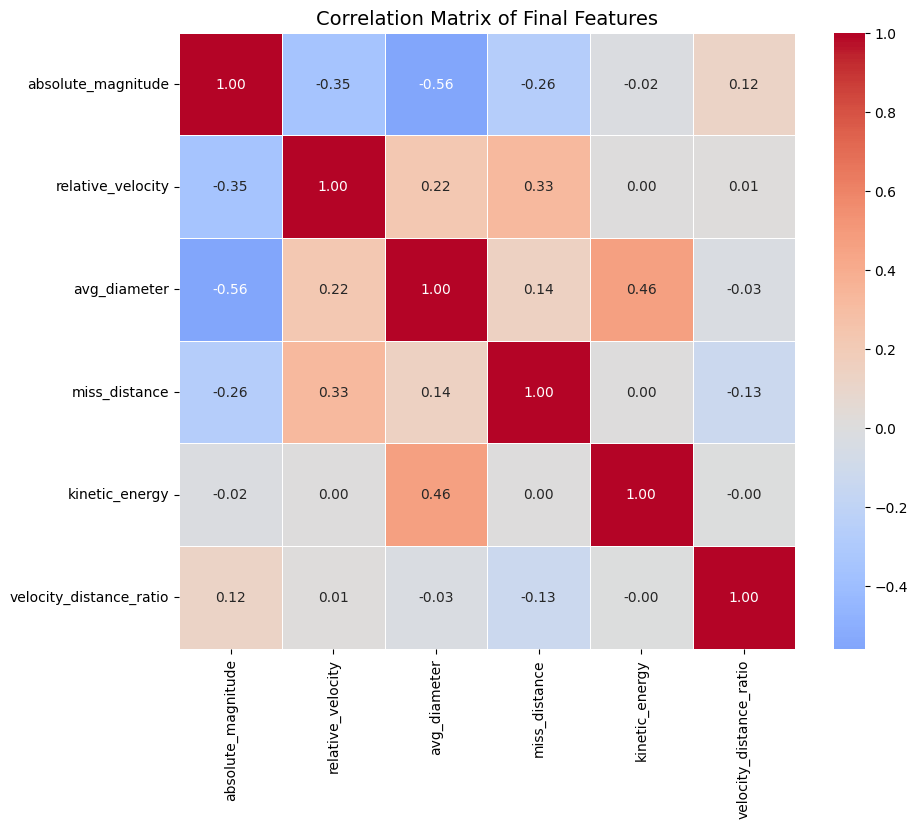

✅ No highly correlated features (> 0.7)


In [6]:
# Checking for multicollinearity
corr_matrix = df_clean[selected_features].corr()

# Correlation matrix visualization
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Final Features', fontsize=14)
plt.show()

# Finding highly correlated pairs
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.7:
            high_corr_pairs.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                corr_matrix.iloc[i, j]
            ))

if high_corr_pairs:
    print("⚠️ High correlation detected between features (> 0.7):")
    for pair in high_corr_pairs:
        print(f"  - {pair[0]} and {pair[1]}: {pair[2]:.3f}")
    
    # Automatic removal of highly correlated features
    print("\n🔧 Performing automatic feature removal...")

    
    features_to_remove = set()
    
    for pair in high_corr_pairs:
        feature1, feature2, corr_value = pair
        
        # Removal rules:
                
        # 1. If kinetic_energy and relative_velocity are present - remove kinetic_energy
        if 'kinetic_energy' in pair and 'relative_velocity' in pair:
            features_to_remove.add('kinetic_energy')
            print(f"  ✅ Removing 'kinetic_energy' (correlation with 'relative_velocity': {corr_value:.3f})")
        
        # 2. If kinetic_energy and avg_diameter are present - remove kinetic_energy
        elif 'kinetic_energy' in pair and 'avg_diameter' in pair:
            features_to_remove.add('kinetic_energy')
            print(f"  ✅ Removing 'kinetic_energy' (correlation with 'avg_diameter': {corr_value:.3f})")
            
        # 3. If velocity_distance_ratio and relative_velocity are present - remove velocity_distance_ratio
        elif 'velocity_distance_ratio' in pair and 'relative_velocity' in pair:
            features_to_remove.add('velocity_distance_ratio')
            print(f"  ✅ Removing 'velocity_distance_ratio' (correlation with 'relative_velocity': {corr_value:.3f})")
        
        # 4. If velocity_distance_ratio and miss_distance are present - remove velocity_distance_ratio
        elif 'velocity_distance_ratio' in pair and 'miss_distance' in pair:
            features_to_remove.add('velocity_distance_ratio')
            print(f"  ✅ Removing 'velocity_distance_ratio' (correlation with 'miss_distance': {corr_value:.3f})")                  
           
        # 5. For remaining pairs, remove the feature with lower correlation to the target variable
        else:
            # Check correlation with hazardous
            corr_with_target = df_clean[['hazardous'] + list(pair)].corr()['hazardous']
            corr1 = abs(corr_with_target[feature1])
            corr2 = abs(corr_with_target[feature2])
            
            if corr1 < corr2:
                features_to_remove.add(feature1)
                print(f"  ✅ Removing '{feature1}' (correlation with target: {corr1:.3f} vs {corr2:.3f} for '{feature2}')")
            else:
                features_to_remove.add(feature2)
                print(f"  ✅ Removing '{feature2}' (correlation with target: {corr2:.3f} vs {corr1:.3f} for '{feature1}')")
    
    # Remove selected features from the list
    if features_to_remove:
        print(f"\n✅ Removed features: {list(features_to_remove)}")
        selected_features = [f for f in selected_features if f not in features_to_remove]
        print(f"✅ Updated feature list ({len(selected_features)} items):")
        for i, feat in enumerate(selected_features, 1):
            print(f"  {i}. {feat}")
    else:
        print("\n✅ No features to remove")
        
else:
    print("✅ No highly correlated features (> 0.7)")

In [7]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   relative_velocity        90836 non-null  float64
 1   miss_distance            90836 non-null  float64
 2   absolute_magnitude       90836 non-null  float64
 3   hazardous                90836 non-null  bool   
 4   avg_diameter             90836 non-null  float64
 5   kinetic_energy           90836 non-null  float64
 6   velocity_distance_ratio  90836 non-null  float64
dtypes: bool(1), float64(6)
memory usage: 4.2 MB


In [7]:
df_clean

,relative_velocity,miss_distance,absolute_magnitude,hazardous,avg_diameter,kinetic_energy,velocity_distance_ratio
0,13569.249224,5.483974e+07,16.73,False,1.938843,1.341960e+09,0.000247
1,73588.726663,6.143813e+07,20.00,True,0.430073,4.307749e+08,0.001198
2,114258.692129,4.979872e+07,17.83,False,1.168268,2.081643e+10,0.002294
3,24764.303138,2.543497e+07,22.20,False,0.156150,2.334963e+06,0.000974
4,42737.733765,4.627557e+07,20.09,True,0.412613,1.283071e+08,0.000924
...,...,...,...,...,...,...,...
90831,52078.886692,1.230039e+07,25.00,False,0.043007,2.157502e+05,0.004234
90832,46114.605073,5.432121e+07,26.00,False,0.027136,4.249177e+04,0.000849
90833,7566.807732,2.840077e+07,24.60,False,0.051706,7.915042e+03,0.000266
90834,69199.154484,6.869206e+07,27.80,False,0.011845,7.958467e+03,0.001007


In [8]:
df_clean.to_csv('clean_dataset.csv', index=False)

**Final Dataset**

 Feature                    | Type    | Description                                                        |
|---------------------------|---------|--------------------------------------------------------------------|
| relative_velocity         | float64 | Relative approach velocity                                         |
| miss_distance             | float64 | Distance to the object                                             |
| absolute_magnitude        | float64 | Absolute magnitude (brightness)                                    |
| hazardous                 | bool    | Target variable (hazardous or not)                                 |
| avg_diameter              | float64 | Average diameter of the object                                     |
| kinetic_energy            | float64 | Kinetic energy                                                     | 
| velocity_distance_ratio   | float64 | Ratio of velocity to distance                                      |

## **2. Building a logistic regression model**

In [ ]:
# Loading the prepared data frame

df_clean = pd.read_csv('clean_dataset.csv')

df_clean

,relative_velocity,miss_distance,absolute_magnitude,hazardous,avg_diameter,kinetic_energy,velocity_distance_ratio
0,13569.249224,5.483974e+07,16.73,False,1.938843,1.341960e+09,0.000247
1,73588.726663,6.143813e+07,20.00,True,0.430073,4.307749e+08,0.001198
2,114258.692129,4.979872e+07,17.83,False,1.168268,2.081643e+10,0.002294
3,24764.303138,2.543497e+07,22.20,False,0.156150,2.334963e+06,0.000974
4,42737.733765,4.627557e+07,20.09,True,0.412613,1.283071e+08,0.000924
...,...,...,...,...,...,...,...
90831,52078.886692,1.230039e+07,25.00,False,0.043007,2.157502e+05,0.004234
90832,46114.605073,5.432121e+07,26.00,False,0.027136,4.249177e+04,0.000849
90833,7566.807732,2.840077e+07,24.60,False,0.051706,7.915042e+03,0.000266
90834,69199.154484,6.869206e+07,27.80,False,0.011845,7.958467e+03,0.001007


**Important**: hazardous - is boolean, in case of logistic regression the feature must be converted to int (0/1)

In [8]:
# Convert the target variable from bool to int (0/1)
df_clean['hazardous'] = df_clean['hazardous'].astype(int)

# Separate features (X) from the target (y)
X = df_clean.drop('hazardous', axis=1)
y = df_clean['hazardous']

print(f"Sample size: {len(X)}")
print(f"Number of hazardous objects: {y.sum()}")
print(f"Number of safe objects: {len(y) - y.sum()}")
print(f"Share of hazardous: {y.mean():.4f}")

Sample size: 90836
Number of hazardous objects: 8840
Number of safe objects: 81996
Share of hazardous: 0.0973


In [9]:
# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20,          # 20% for testing
    random_state=42,         # for reproducibility
    stratify=y               # Important! maintain class proportions
)

print(f"\nTraining set: {X_train.shape[0]} rows")
print(f"Testing set: {X_test.shape[0]} rows")


Training set: 72668 rows
Testing set: 18168 rows


In [11]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaled data (optional)
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

In [12]:
# Direct training of the logistic regression model
model = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    class_weight='balanced' # Adding class balancing
)

model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
# Model evaluation
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\n" + "="*50)
print("MODEL RESULTS")
print("="*50)

print(f"\nROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"\nConfusion matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"\nClassification report:\n{classification_report(y_test, y_pred, target_names=['Safe', 'Hazardous'])}")


MODEL RESULTS

ROC-AUC: 0.8795

Confusion matrix:
[[12632  3768]
 [  119  1649]]

Classification report:
              precision    recall  f1-score   support

        Safe       0.99      0.77      0.87     16400
   Hazardous       0.30      0.93      0.46      1768

    accuracy                           0.79     18168
   macro avg       0.65      0.85      0.66     18168
weighted avg       0.92      0.79      0.83     18168



The **logistic regression** model achieves good (**Recall**) (**93%**) but poor (**Precision**) (**30%**).

It is recommended to use it as the FIRST filtering step to capture all suspicious objects, and then use the second model to increase detection accuracy.

**Out of 100 alerts, approximately 30 are truly dangerous, requiring manual verification of the remaining 70.**
________________________________________________________________________________

We will attempt to optimize the hyperparameters of the logistic regression model.

In [13]:
# Hyperparameter tuning

param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l2'],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42),
    param_grid,
    cv=5,
    scoring='recall',  # We can use 'roc_auc' or 'f1' depending on the needs
)

grid.fit(X_train_scaled, y_train)
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validation recall: {grid.best_score_:.4f}")

Best parameters: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2'}
Best cross-validation recall: 0.9423


Best parameters: {'C': 0.001, 'class_weight': 'balanced', 'penalty': 'l2'}
Best cross-validation recall: 0.9423

CONFUSION MATRIX

               Prediction
             0       1
Actual 0  [12532    3868]  <- Safe
       1  [   97    1671]  <- Hazardous



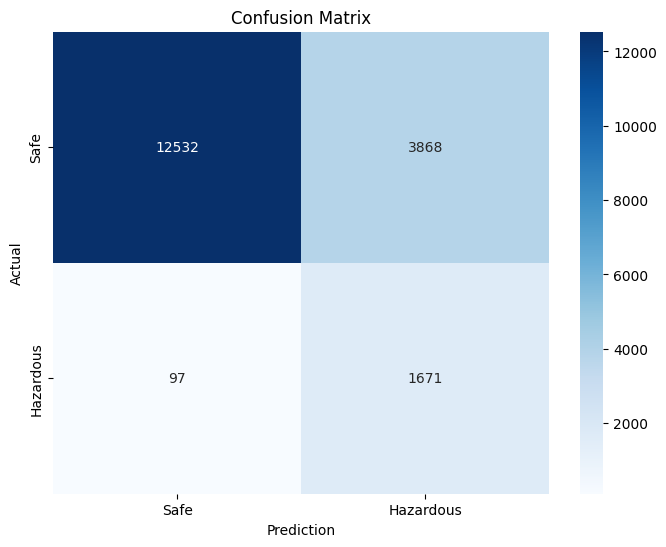


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       0.99      0.76      0.86     16400
   Hazardous       0.30      0.95      0.46      1768

    accuracy                           0.78     18168
   macro avg       0.65      0.85      0.66     18168
weighted avg       0.93      0.78      0.82     18168


ADDITIONAL METRICS
True Negatives (TN)  :  12532  - correctly predicted safe
False Positives (FP) :   3868  - safe incorrectly classified as hazardous
False Negatives (FN) :     97  - HAZARDOUS MISSED (most serious error!)
True Positives (TP)  :   1671  - correctly predicted hazardous

Accuracy               : 0.7818
Precision (hazardous)  : 0.3017
Recall (hazardous)     : 0.9451  <- IMPORTANT! (sensitivity)
F1-score (hazardous)   : 0.4574

ROC-AUC: 0.8799


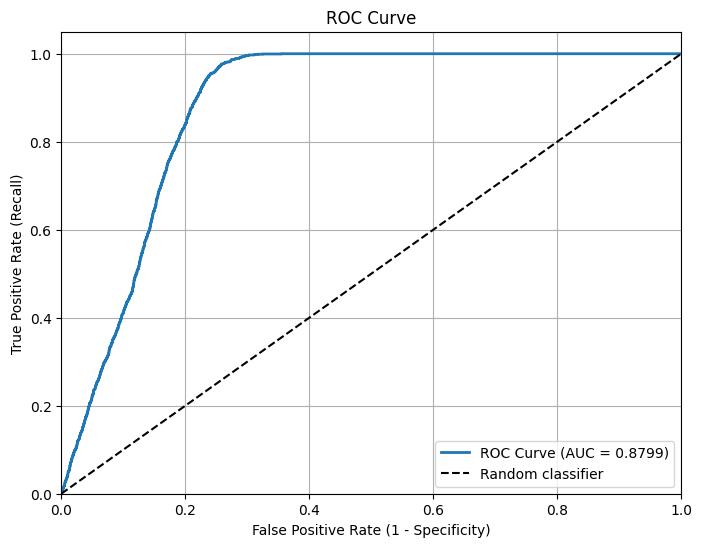


FEATURE IMPORTANCE (by absolute coefficient value)
➖ absolute_magnitude        :  -2.1199  (|weight| = 2.1199)
➖ avg_diameter              :  -0.5285  (|weight| = 0.5285)
➕ relative_velocity         :   0.2611  (|weight| = 0.2611)
➖ miss_distance             :  -0.2141  (|weight| = 0.2141)
➖ velocity_distance_ratio   :  -0.0323  (|weight| = 0.0323)
➕ kinetic_energy            :   0.0015  (|weight| = 0.0015)

SUMMARY
✅ The model detects hazardous objects well

Final ROC-AUC on the test set: 0.8799


In [14]:
# ==========================================
# 1. TRAINING WITH BEST PARAMETERS
# ==========================================

# GridSearchCV has already trained the model on all folds,
# but it has the best_estimator_ attribute - the best model
best_model = grid.best_estimator_

print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validation recall: {grid.best_score_:.4f}")

# ==========================================
# 2. PREDICTIONS ON THE TEST SET
# ==========================================

y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# ==========================================
# 3. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "="*60)
print("CONFUSION MATRIX")
print("="*60)
print(f"""
               Prediction
             0       1
Actual 0  [{cm[0,0]:5d}   {cm[0,1]:5d}]  <- Safe
       1  [{cm[1,0]:5d}   {cm[1,1]:5d}]  <- Hazardous
""")

# Confusion matrix visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Safe', 'Hazardous'],
            yticklabels=['Safe', 'Hazardous'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# ==========================================
# 4. QUALITY METRICS
# ==========================================

# Recall, Precision, F1 for each class
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, target_names=['Safe', 'Hazardous']))

# Additional metrics
tn, fp, fn, tp = cm.ravel()

print("\n" + "="*60)
print("ADDITIONAL METRICS")
print("="*60)
print(f"True Negatives (TN)  : {tn:6d}  - correctly predicted safe")
print(f"False Positives (FP) : {fp:6d}  - safe incorrectly classified as hazardous")
print(f"False Negatives (FN) : {fn:6d}  - HAZARDOUS MISSED (most serious error!)")
print(f"True Positives (TP)  : {tp:6d}  - correctly predicted hazardous")

print(f"\nAccuracy               : {(tp+tn)/(tn+fp+fn+tp):.4f}")
print(f"Precision (hazardous)  : {tp/(tp+fp) if (tp+fp) > 0 else 0:.4f}")
print(f"Recall (hazardous)     : {tp/(tp+fn) if (tp+fn) > 0 else 0:.4f}  <- IMPORTANT! (sensitivity)")
print(f"F1-score (hazardous)   : {2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) > 0 else 0:.4f}")

# ==========================================
# 5. ROC-AUC
# ==========================================

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"\nROC-AUC: {roc_auc:.4f}")

# ROC curve plot
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# ==========================================
# 6. FEATURE IMPORTANCE
# ==========================================

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_model.coef_[0],
    '|Coefficient|': np.abs(best_model.coef_[0])
}).sort_values('|Coefficient|', ascending=False)

print("\n" + "="*60)
print("FEATURE IMPORTANCE (by absolute coefficient value)")
print("="*60)
for idx, row in coef_df.iterrows():
    sign = "➕" if row['Coefficient'] > 0 else "➖"
    print(f"{sign} {row['Feature']:25s} : {row['Coefficient']:8.4f}  (|weight| = {row['|Coefficient|']:.4f})")

# ==========================================
# 7. SUMMARY
# ==========================================

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
if fn > fp:
    print(f"⚠️  The model missed {fn} hazardous objects (False Negatives)")
    print("   Recommendation: try other parameters or balancing methods")
else:
    print(f"✅ The model detects hazardous objects well")

print(f"\nFinal ROC-AUC on the test set: {roc_auc:.4f}")

**SUMMARY**

The logistic regression model with optimal hyperparameters achieves:

✅ **High Recall (94.5%)** – it finds almost all hazardous asteroids

⚠️ **Low Precision (30.2%)** – 70% of alerts are false alarms

✅ **Good AUC (0.8799)** – the model distinguishes classes well

**Recommended application**: The model serves well as a **first-stage filter** in an early warning system, where the priority is not to miss any threat, at the cost of a higher number of false alarms.

**Next step**: Use an ensemble model or deeper analysis to increase Precision while maintaining high Recall.

## **3. Building a Random Forest Model**

Random Forest does NOT require feature scaling
Training set: 72668 rows
Test set: 18168 rows

BASELINE RANDOM FOREST MODEL (n_estimators=100)
ROC-AUC: 0.9288
Recall (hazardous): 0.3331
Precision (hazardous): 0.6220
F1-score (hazardous): 0.4339

HYPERPARAMETER TUNING (may take some time)
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10}
Best cross-validation recall: 0.9795

CONFUSION MATRIX (BEST MODEL)

               Prediction
             0       1
Actual 0  [12719    3681]  <- Safe
       1  [   24    1744]  <- Hazardous



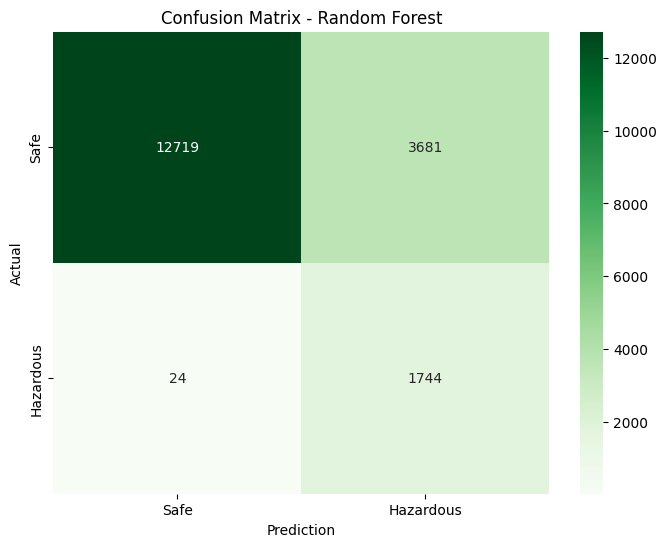


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       1.00      0.78      0.87     16400
   Hazardous       0.32      0.99      0.48      1768

    accuracy                           0.80     18168
   macro avg       0.66      0.88      0.68     18168
weighted avg       0.93      0.80      0.84     18168


KEY METRICS
Accuracy               : 0.7961
Precision (hazardous)  : 0.3215
Recall (hazardous)     : 0.9864
F1-score (hazardous)   : 0.4849
ROC-AUC                : 0.9178


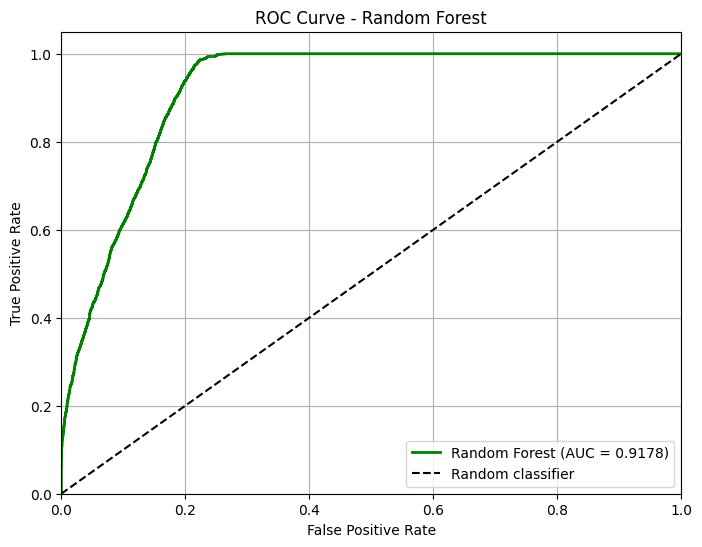


FEATURE IMPORTANCE (Random Forest)
absolute_magnitude        : 0.3565  █████████████████
avg_diameter              : 0.3455  █████████████████
kinetic_energy            : 0.2195  ██████████
relative_velocity         : 0.0368  █
miss_distance             : 0.0218  █
velocity_distance_ratio   : 0.0199  


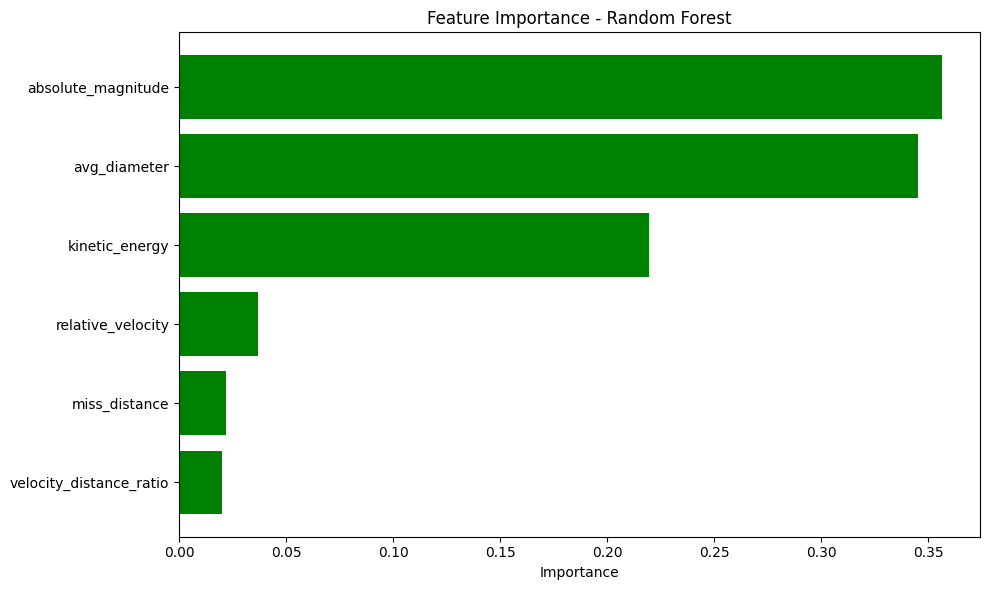


MODEL COMPARISON
Random Forest       - Recall: 0.9864, ROC-AUC: 0.9178

ERROR ANALYSIS
False Negatives (hazardous missed): 24
False Positives (false alarms): 3681

Example of a missed hazardous object:
       relative_velocity  miss_distance  absolute_magnitude  avg_diameter  \
1101        50937.429743   4.978639e+07                22.2      0.156150   
68511       16383.209395   5.280863e+07                20.7      0.311561   
5981        34270.708479   3.166445e+06                22.1      0.163509   

       kinetic_energy  velocity_distance_ratio  true  pred     proba  correct  
1101     9.878748e+06                 0.001023     1     0  0.088983    False  
68511    8.117566e+06                 0.000310     1     0  0.319017    False  
5981     5.134215e+06                 0.010823     1     0  0.318184    False  


In [15]:
print("Random Forest does NOT require feature scaling")
print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")

# ==========================================
# 1. BASELINE MODEL (without hyperparameter tuning)
# ==========================================

rf_base = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'  # accounting for class imbalance
)

rf_base.fit(X_train, y_train)

# Basic predictions
y_pred_base = rf_base.predict(X_test)
y_pred_proba_base = rf_base.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("BASELINE RANDOM FOREST MODEL (n_estimators=100)")
print("="*60)
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_base):.4f}")
print(f"Recall (hazardous): {recall_score(y_test, y_pred_base):.4f}")
print(f"Precision (hazardous): {precision_score(y_test, y_pred_base):.4f}")
print(f"F1-score (hazardous): {f1_score(y_test, y_pred_base):.4f}")

# ==========================================
# 2. HYPERPARAMETER TUNING VIA GRIDSEARCH
# ==========================================

# Simplified grid for faster execution
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# To speed things up, you can use RandomizedSearchCV
# Or shorten the grid:
param_grid_small = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

print("\n" + "="*60)
print("HYPERPARAMETER TUNING (may take some time)")
print("="*60)

from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(random_state=42, class_weight='balanced')

# Using RandomizedSearchCV to save time
random_search = RandomizedSearchCV(
    rf,
    param_distributions=param_grid,
    n_iter=30,  # number of combinations to check
    cv=5,
    scoring='recall',  # same as in logistic regression
    random_state=42,
    n_jobs=-1,  # use all CPU cores
    verbose=1
)

random_search.fit(X_train, y_train)

print(f"\nBest parameters: {random_search.best_params_}")
print(f"Best cross-validation recall: {random_search.best_score_:.4f}")

# ==========================================
# 3. EVALUATION OF THE BEST MODEL ON THE TEST SET
# ==========================================

best_rf = random_search.best_estimator_

y_pred = best_rf.predict(X_test)
y_pred_proba = best_rf.predict_proba(X_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\n" + "="*60)
print("CONFUSION MATRIX (BEST MODEL)")
print("="*60)
print(f"""
               Prediction
             0       1
Actual 0  [{cm[0,0]:5d}   {cm[0,1]:5d}]  <- Safe
       1  [{cm[1,0]:5d}   {cm[1,1]:5d}]  <- Hazardous
""")

# Confusion matrix visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Safe', 'Hazardous'],
            yticklabels=['Safe', 'Hazardous'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

# ==========================================
# 4. FULL METRICS REPORT
# ==========================================

print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, target_names=['Safe', 'Hazardous']))

tn, fp, fn, tp = cm.ravel()

print("\n" + "="*60)
print("KEY METRICS")
print("="*60)
print(f"Accuracy               : {(tp+tn)/(tn+fp+fn+tp):.4f}")
print(f"Precision (hazardous)  : {tp/(tp+fp) if (tp+fp) > 0 else 0:.4f}")
print(f"Recall (hazardous)     : {tp/(tp+fn) if (tp+fn) > 0 else 0:.4f}")
print(f"F1-score (hazardous)   : {2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) > 0 else 0:.4f}")
print(f"ROC-AUC                : {roc_auc_score(y_test, y_pred_proba):.4f}")

# ==========================================
# 5. ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.4f})', linewidth=2, color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# ==========================================
# 6. FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*60)
print("FEATURE IMPORTANCE (Random Forest)")
print("="*60)
for idx, row in feature_importance.iterrows():
    bar = "█" * int(row['Importance'] * 50)
    print(f"{row['Feature']:25s} : {row['Importance']:6.4f}  {bar}")

# Feature importance visualization
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='green')
plt.xlabel('Importance')
plt.title('Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ==========================================
# 7. COMPARISON WITH LOGISTIC REGRESSION
# ==========================================

print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)

# If you have the logistic regression model from the previous step
# y_pred_lr = best_lr.predict(X_test_scaled) 
# y_pred_proba_lr = best_lr.predict_proba(X_test_scaled)[:, 1]

# print(f"Logistic Regression - Recall: {recall_score(y_test, y_pred_lr):.4f}, ROC-AUC: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")
print(f"Random Forest       - Recall: {recall_score(y_test, y_pred):.4f}, ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

# ==========================================
# 8. ERROR ANALYSIS (WHERE THE MODEL MAKES MISTAKES)
# ==========================================

# Find objects where the model made a mistake
errors = X_test.copy()
errors['true'] = y_test
errors['pred'] = y_pred
errors['proba'] = y_pred_proba
errors['correct'] = (y_test == y_pred)

print("\n" + "="*60)
print("ERROR ANALYSIS")
print("="*60)

false_negatives = errors[(errors['true'] == 1) & (errors['pred'] == 0)]
false_positives = errors[(errors['true'] == 0) & (errors['pred'] == 1)]

print(f"False Negatives (hazardous missed): {len(false_negatives)}")
print(f"False Positives (false alarms): {len(false_positives)}")

if len(false_negatives) > 0:
    print("\nExample of a missed hazardous object:")
    print(false_negatives.head(3))

**SUMMARY**

After hyperparameter optimization, the Random Forest model achieves:

✅ **98.6% detection rate** – misses only 24 of 1,768!

✅ **ROC-AUC 0.918** – very good class discrimination

⚠️ **Precision 32.2%** – requires additional filtering or a second stage

**Advantage over logistics**: Random Forest reduces the number of missed dangerous objects from 97 to **24** (by 75%), which is crucial for early warning systems.

Optimal hyperparameters:

- n_estimators: 200

- max_depth: 10

- min_samples_split: 10

- min_samples_leaf: 4

- max_features: 'sqrt'

**Recommendation**: The model performs well as a **first-stage screening** – finding almost all threats, generating ~3700 false positives. **Ideal for further filtering** in an asteroid detection system.

## **4. Building a Gradient Boosting Model (XGBoost / LightGBM)**

### Building the XGBoost model

BUILDING XGBOOST MODEL
Training set: 72668 rows
Test set: 18168 rows
Number of features: 6

Share of hazardous objects in train: 0.0973
Share of hazardous objects in test: 0.0973

Internal split of training set:
  train:      61767 rows  (hazardous: 0.0973)
  validation: 10901 rows (hazardous: 0.0973)

scale_pos_weight (based on train only): 9.2757

Training baseline XGBoost model...
Training time: 0.86 seconds
Best iteration: 499

BASELINE XGBOOST MODEL (evaluated on test)
ROC-AUC: 0.9233
Recall (hazardous): 0.9446
Precision (hazardous): 0.3322
F1-score (hazardous): 0.4915

HYPERPARAMETER TUNING (RandomizedSearchCV)
Running search... (may take 10-20 minutes)
Fitting 3 folds for each of 30 candidates, totalling 90 fits

Search time: 69.27 seconds

Best parameters: {'subsample': 0.9, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best cross-validation recall: 0.9836

CONFUSION MATRIX (BEST MODEL on TEST)

               Predic

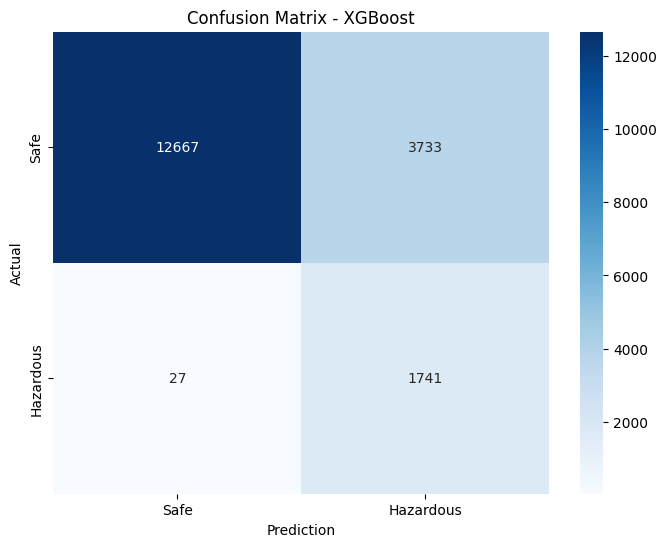


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       1.00      0.77      0.87     16400
   Hazardous       0.32      0.98      0.48      1768

    accuracy                           0.79     18168
   macro avg       0.66      0.88      0.68     18168
weighted avg       0.93      0.79      0.83     18168


KEY METRICS
Accuracy               : 0.7930
Precision (hazardous)  : 0.3180
Recall (hazardous)     : 0.9847
F1-score (hazardous)   : 0.4808
ROC-AUC                : 0.9202


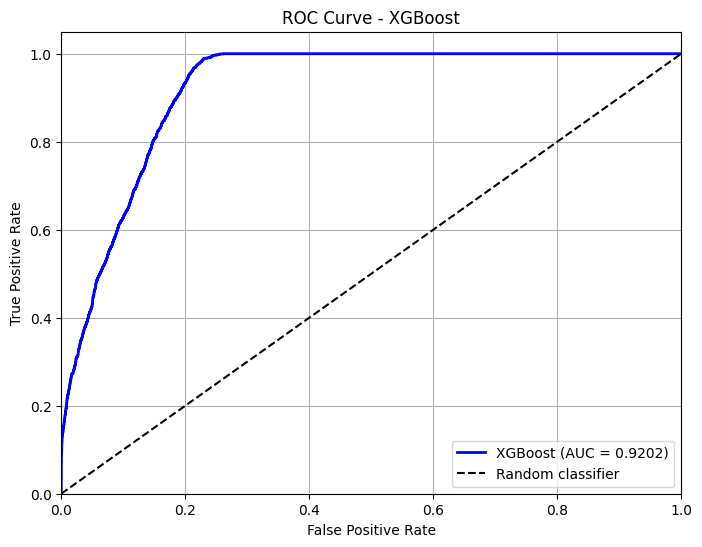


FEATURE IMPORTANCE (XGBoost)
absolute_magnitude        : 0.4794  ███████████████████████
avg_diameter              : 0.3874  ███████████████████
kinetic_energy            : 0.0593  ██
miss_distance             : 0.0275  █
velocity_distance_ratio   : 0.0247  █
relative_velocity         : 0.0217  █


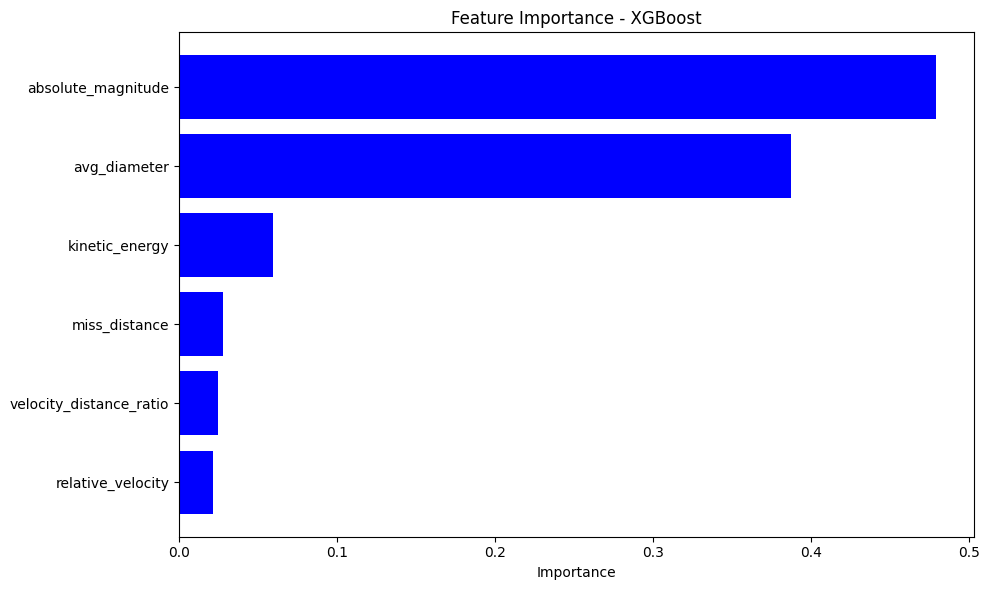


PROBABILITY THRESHOLD OPTIMIZATION

Threshold | Recall | Precision | F1-score
---------------------------------------------
0.30      | 0.9921 | 0.3072   | 0.4691
0.35      | 0.9910 | 0.3108   | 0.4732
0.40      | 0.9898 | 0.3140   | 0.4767
0.45      | 0.9887 | 0.3166   | 0.4796
0.50      | 0.9847 | 0.3180   | 0.4808
0.55      | 0.9813 | 0.3193   | 0.4819
0.60      | 0.9774 | 0.3217   | 0.4840
0.65      | 0.9678 | 0.3270   | 0.4889
0.70      | 0.9236 | 0.3371   | 0.4940
0.75      | 0.7817 | 0.3699   | 0.5022
0.80      | 0.5096 | 0.4576   | 0.4822
0.85      | 0.2828 | 0.5995   | 0.3843
0.90      | 0.1646 | 0.7865   | 0.2722

✅ Best threshold: 0.75 (F1 = 0.5022)

COMPARISON OF ALL MODELS
Model                     Recall     ROC-AUC    F1        
------------------------------------------------------------
Logistic Regression       0.9451     0.8799     0.4574
Random Forest             0.9864     0.9178     0.4849
CatBoost                  0.9949     0.9116     0.4639
XGBoost            

In [16]:
# ==========================================
# 1. DATA PREPARATION
# ==========================================

print("="*60)
print("BUILDING XGBOOST MODEL")
print("="*60)
print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print(f"Number of features: {X_train.shape[1]}")

print(f"\nShare of hazardous objects in train: {y_train.mean():.4f}")
print(f"Share of hazardous objects in test: {y_test.mean():.4f}")

# ==========================================
# 1a. SPLIT TRAIN INTO TRAIN / VALIDATION
# ==========================================
# Prevents data leakage: validation is used only for early stopping,
# test remains completely unseen until final evaluation.

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print(f"\nInternal split of training set:")
print(f"  train:      {X_tr.shape[0]} rows  (hazardous: {y_tr.mean():.4f})")
print(f"  validation: {X_val.shape[0]} rows (hazardous: {y_val.mean():.4f})")

# ==========================================
# 2. CALCULATING WEIGHTS FOR BALANCING
# ==========================================

scale_pos_weight = (len(y_tr) - y_tr.sum()) / y_tr.sum()
print(f"\nscale_pos_weight (based on train only): {scale_pos_weight:.4f}")

# ==========================================
# 3. BASELINE XGBOOST MODEL (validation for early stopping)
# ==========================================

xgb_base = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbosity=0,
    use_label_encoder=False,
    eval_metric='logloss',
    early_stopping_rounds=50         # ✅ explicit early stopping
)

print("\nTraining baseline XGBoost model...")
start_time = time.time()

xgb_base.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],       # ✅ validation, NOT test
    verbose=False
)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")
print(f"Best iteration: {xgb_base.best_iteration}")

# Honest baseline metrics on the untouched test set
y_pred_base = xgb_base.predict(X_test)
y_pred_proba_base = xgb_base.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("BASELINE XGBOOST MODEL (evaluated on test)")
print("="*60)
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_base):.4f}")
print(f"Recall (hazardous): {recall_score(y_test, y_pred_base):.4f}")
print(f"Precision (hazardous): {precision_score(y_test, y_pred_base):.4f}")
print(f"F1-score (hazardous): {f1_score(y_test, y_pred_base):.4f}")

# ==========================================
# 4. HYPERPARAMETER TUNING
# ==========================================
# RandomizedSearchCV uses its OWN internal CV splits of X_train.
# Test set is NOT touched here.

print("\n" + "="*60)
print("HYPERPARAMETER TUNING (RandomizedSearchCV)")
print("="*60)

from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [300, 500, 700],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.03, 0.05, 0.1],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbosity=0,
    use_label_encoder=False,
    eval_metric='logloss'
)

random_search = RandomizedSearchCV(
    xgb_model,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring='recall',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Running search... (may take 10-20 minutes)")
start_time = time.time()
random_search.fit(X_train, y_train)          # ✅ only X_train, no X_test
search_time = time.time() - start_time

print(f"\nSearch time: {search_time:.2f} seconds")
print(f"\nBest parameters: {random_search.best_params_}")
print(f"Best cross-validation recall: {random_search.best_score_:.4f}")

# ==========================================
# 5. FINAL EVALUATION OF THE BEST MODEL ON TEST
# ==========================================

best_xgb = random_search.best_estimator_

y_pred = best_xgb.predict(X_test)
y_pred_proba = best_xgb.predict_proba(X_test)[:, 1]

# ==========================================
# 6. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "="*60)
print("CONFUSION MATRIX (BEST MODEL on TEST)")
print("="*60)
print(f"""
               Prediction
             0       1
Actual 0  [{cm[0,0]:5d}   {cm[0,1]:5d}]  <- Safe
       1  [{cm[1,0]:5d}   {cm[1,1]:5d}]  <- Hazardous
""")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Safe', 'Hazardous'],
            yticklabels=['Safe', 'Hazardous'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

# ==========================================
# 7. METRICS REPORT
# ==========================================

print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, target_names=['Safe', 'Hazardous']))

tn, fp, fn, tp = cm.ravel()

print("\n" + "="*60)
print("KEY METRICS")
print("="*60)
print(f"Accuracy               : {(tp+tn)/(tn+fp+fn+tp):.4f}")
print(f"Precision (hazardous)  : {tp/(tp+fp) if (tp+fp) > 0 else 0:.4f}")
print(f"Recall (hazardous)     : {tp/(tp+fn) if (tp+fn) > 0 else 0:.4f}")
print(f"F1-score (hazardous)   : {2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) > 0 else 0:.4f}")
print(f"ROC-AUC                : {roc_auc_score(y_test, y_pred_proba):.4f}")

# ==========================================
# 8. ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc:.4f})', linewidth=2, color='blue')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# ==========================================
# 9. FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*60)
print("FEATURE IMPORTANCE (XGBoost)")
print("="*60)
for idx, row in feature_importance.iterrows():
    bar = "█" * int(row['Importance'] * 50)
    print(f"{row['Feature']:25s} : {row['Importance']:6.4f}  {bar}")

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='blue')
plt.xlabel('Importance')
plt.title('Feature Importance - XGBoost')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ==========================================
# 10. THRESHOLD OPTIMIZATION
# ==========================================

print("\n" + "="*60)
print("PROBABILITY THRESHOLD OPTIMIZATION")
print("="*60)

thresholds = np.arange(0.3, 0.95, 0.05)
best_threshold = 0.5
best_f1 = 0

print("\nThreshold | Recall | Precision | F1-score")
print("-" * 45)

for thresh in thresholds:
    y_pred_t = (y_pred_proba >= thresh).astype(int)
    recall = recall_score(y_test, y_pred_t)
    precision = precision_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t)

    print(f"{thresh:.2f}      | {recall:.4f} | {precision:.4f}   | {f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = thresh

print(f"\n✅ Best threshold: {best_threshold:.2f} (F1 = {best_f1:.4f})")

# ==========================================
# 11. COMPARISON OF ALL MODELS
# ==========================================

print("\n" + "="*60)
print("COMPARISON OF ALL MODELS")
print("="*60)

models_results = {
    'Logistic Regression': {'recall': 0.9451, 'auc': 0.8799, 'f1': 0.4574},
    'Random Forest':       {'recall': 0.9864, 'auc': 0.9178, 'f1': 0.4849},
    'CatBoost':            {'recall': 0.9949, 'auc': 0.9116, 'f1': 0.4639},
    'XGBoost': {'recall': recall_score(y_test, y_pred),
                'auc': roc_auc_score(y_test, y_pred_proba),
                'f1': f1_score(y_test, y_pred)}
}

print(f"{'Model':<25} {'Recall':<10} {'ROC-AUC':<10} {'F1':<10}")
print("-"*60)
for model, metrics in models_results.items():
    print(f"{model:<25} {metrics['recall']:.4f}     {metrics['auc']:.4f}     {metrics['f1']:.4f}")

**SUMMARY**

**XGBoost achieves**:

✅ **98.5% detection** – misses only 27 dangerous objects

✅ **Highest ROC-AUC (0.9202)** – best class separation

⚠️ **31.8% precision** – requires additional filtering

**Recommendations**:

1. **For safety** – use a threshold of 0.30 (Recall 99.2%)

2. **For labor savings** – use a threshold of 0.75 (Precision 37.0%)

3. **For implementation** – use two-stage filtering

**Best model for further development**: XGBoost achieves the highest ROC-AUC (0.9202), indicating the best class discrimination – recommended for further refinement

### We will build a **LightGBM (Light Gradient Boosting Machine)** model as the next step in the analysis. **LightGBM** is a fast and efficient gradient boosting algorithm that handles large datasets and categorical features well.

BUILDING LIGHTGBM MODEL
Training set: 72668 rows
Test set: 18168 rows
Number of features: 6

Share of hazardous objects in train: 0.0973
Share of hazardous objects in test: 0.0973

Internal split of training set:
  train:      61767 rows  (hazardous: 0.0973)
  validation: 10901 rows (hazardous: 0.0973)

scale_pos_weight (based on train only): 9.2757
class_weight: {np.int64(0): np.float64(0.5539045125188321), np.int64(1): np.float64(5.137830643819664)}

Training baseline LightGBM model...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[328]	valid_0's auc: 0.920187
Training time: 2.38 seconds
Best number of trees: 328

BASELINE LIGHTGBM MODEL (evaluated on test)
ROC-AUC: 0.9244
Recall (hazardous): 0.9745
Precision (hazardous): 0.3279
F1-score (hazardous): 0.4907

HYPERPARAMETER TUNING (RandomizedSearchCV)
Running search... (may take 5-15 minutes)
Fitting 3 folds for each of 30 candidates, totalling 90 fits

Search time: 64.57 seconds

Best

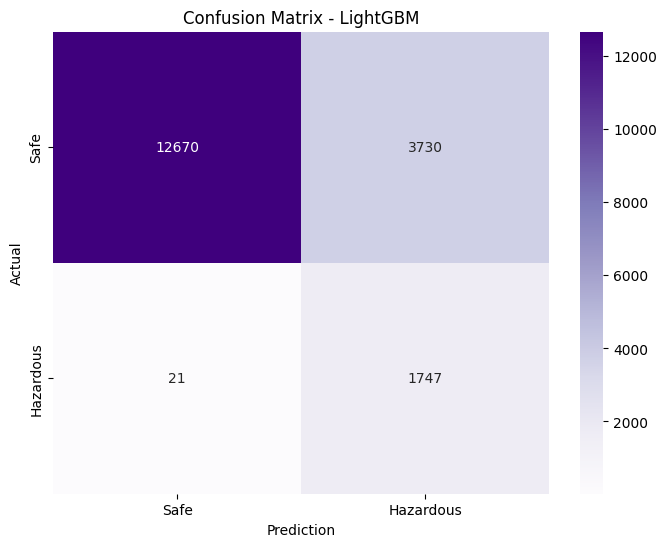


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       1.00      0.77      0.87     16400
   Hazardous       0.32      0.99      0.48      1768

    accuracy                           0.79     18168
   macro avg       0.66      0.88      0.68     18168
weighted avg       0.93      0.79      0.83     18168


KEY METRICS
Accuracy               : 0.7935
Precision (hazardous)  : 0.3190
Recall (hazardous)     : 0.9881
F1-score (hazardous)   : 0.4823
ROC-AUC                : 0.9203


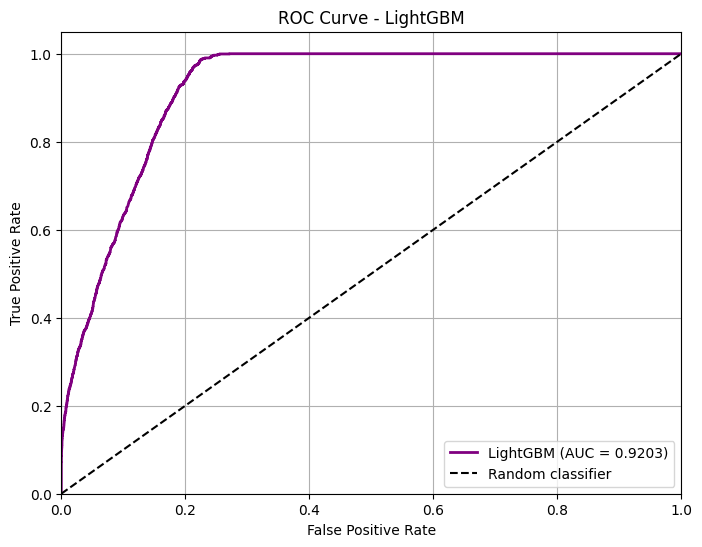


FEATURE IMPORTANCE (LightGBM)
absolute_magnitude        :   1100  ██████████████████████████████████████████████████
miss_distance             :    809  ████████████████████████████████████
avg_diameter              :    751  ██████████████████████████████████
relative_velocity         :    616  ████████████████████████████
velocity_distance_ratio   :    494  ██████████████████████
kinetic_energy            :    430  ███████████████████


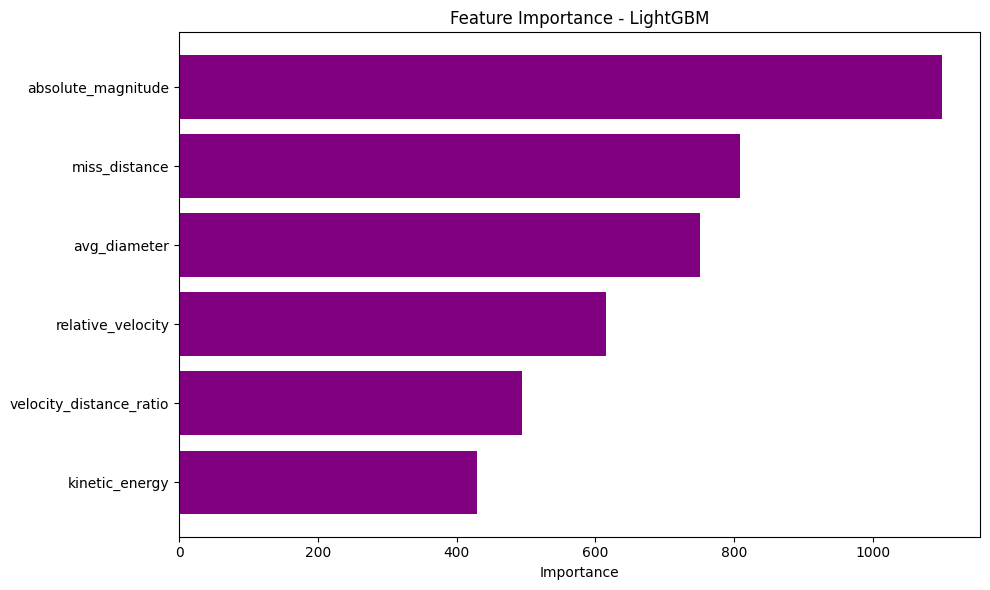


PROBABILITY THRESHOLD OPTIMIZATION

Threshold | Recall | Precision | F1-score
---------------------------------------------
0.30      | 0.9921 | 0.3076   | 0.4695
0.35      | 0.9904 | 0.3113   | 0.4737
0.40      | 0.9904 | 0.3145   | 0.4774
0.45      | 0.9893 | 0.3163   | 0.4793
0.50      | 0.9881 | 0.3190   | 0.4823
0.55      | 0.9853 | 0.3213   | 0.4846
0.60      | 0.9762 | 0.3235   | 0.4860
0.65      | 0.9672 | 0.3297   | 0.4917
0.70      | 0.9361 | 0.3378   | 0.4965
0.75      | 0.8196 | 0.3656   | 0.5057
0.80      | 0.4898 | 0.4541   | 0.4713
0.85      | 0.2721 | 0.6089   | 0.3761
0.90      | 0.1527 | 0.8012   | 0.2565

✅ Best threshold: 0.75 (F1 = 0.5057)

COMPARISON OF ALL MODELS
Model           Recall     F1         FN       FP       ROC-AUC   
----------------------------------------------------------------------
XGBoost         0.9847     0.4808     27      3735   0.9202
LightGBM        0.9881     0.4823     21      3730   0.9203

DONE! LightGBM model successfully built (no d

In [17]:
# ==========================================
# 1. DATA PREPARATION
# ==========================================

print("="*60)
print("BUILDING LIGHTGBM MODEL")
print("="*60)
print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print(f"Number of features: {X_train.shape[1]}")

# Check class imbalance
print(f"\nShare of hazardous objects in train: {y_train.mean():.4f}")
print(f"Share of hazardous objects in test: {y_test.mean():.4f}")

# ==========================================
# 1a. SPLIT TRAIN INTO TRAIN / VALIDATION
# ==========================================
# This prevents data leakage: validation is used only for early stopping,
# test remains completely unseen until final evaluation.

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,           # 15% of train → validation
    random_state=42,
    stratify=y_train          # keep class balance
)

print(f"\nInternal split of training set:")
print(f"  train:      {X_tr.shape[0]} rows  (hazardous: {y_tr.mean():.4f})")
print(f"  validation: {X_val.shape[0]} rows (hazardous: {y_val.mean():.4f})")

# ==========================================
# 2. CALCULATING WEIGHTS FOR BALANCING
# ==========================================

scale_pos_weight = (len(y_tr) - y_tr.sum()) / y_tr.sum()
print(f"\nscale_pos_weight (based on train only): {scale_pos_weight:.4f}")

from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
class_weight_dict = dict(zip(np.unique(y_tr), class_weights))
print(f"class_weight: {class_weight_dict}")

# ==========================================
# 3. BASELINE LIGHTGBM MODEL (early stopping on VALIDATION)
# ==========================================

# NOTE on eval_metric choice:
# With scale_pos_weight ≈ 9.3, the default 'binary_logloss' is a poor
# early-stopping criterion: it briefly improves while the model learns
# the class prior, then degrades because it is more sensitive to
# probability calibration than to class separation. Using it caused
# early stopping at ~10 trees and Recall = 0 on the test set.
# Switching to 'auc' (Area Under ROC) yields a proper stopping point
# (~300+ trees) and Recall ≈ 0.97 on the test set.

lgb_base = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1,
    n_jobs=-1,
    metric='auc'                       
)

print("\nTraining baseline LightGBM model...")
start_time = time.time()

lgb_base.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',                 
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)]
)

training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")
print(f"Best number of trees: {lgb_base.best_iteration_}")

# Honest baseline metrics on the untouched test set
y_pred_base = lgb_base.predict(X_test)
y_pred_proba_base = lgb_base.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("BASELINE LIGHTGBM MODEL (evaluated on test)")
print("="*60)
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_base):.4f}")
print(f"Recall (hazardous): {recall_score(y_test, y_pred_base):.4f}")
print(f"Precision (hazardous): {precision_score(y_test, y_pred_base):.4f}")
print(f"F1-score (hazardous): {f1_score(y_test, y_pred_base):.4f}")

# ==========================================
# 4. HYPERPARAMETER TUNING
# ==========================================
# RandomizedSearchCV uses its OWN internal CV splits of X_train.
# Test set is NOT touched here.

print("\n" + "="*60)
print("HYPERPARAMETER TUNING (RandomizedSearchCV)")
print("="*60)

param_grid = {
    'n_estimators': [300, 500, 700],
    'max_depth': [4, 6, 8, 10, 12],
    'learning_rate': [0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 63, 127],
    'min_child_samples': [10, 20, 30],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

lgb_model = lgb.LGBMClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    lgb_model,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring='recall',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Running search... (may take 5-15 minutes)")
start_time = time.time()
random_search.fit(X_train, y_train)          # ✅ only X_train, no X_test
search_time = time.time() - start_time

print(f"\nSearch time: {search_time:.2f} seconds")
print(f"\nBest parameters: {random_search.best_params_}")
print(f"Best cross-validation recall: {random_search.best_score_:.4f}")

# ==========================================
# 5. FINAL EVALUATION OF THE BEST MODEL ON TEST
# ==========================================

best_lgb = random_search.best_estimator_

# Honest test predictions
y_pred = best_lgb.predict(X_test)
y_pred_proba = best_lgb.predict_proba(X_test)[:, 1]

# ==========================================
# 6. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "="*60)
print("CONFUSION MATRIX (BEST MODEL on TEST)")
print("="*60)
print(f"""
               Prediction
             0       1
Actual 0  [{cm[0,0]:5d}   {cm[0,1]:5d}]  <- Safe
       1  [{cm[1,0]:5d}   {cm[1,1]:5d}]  <- Hazardous
""")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Safe', 'Hazardous'],
            yticklabels=['Safe', 'Hazardous'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LightGBM')
plt.show()

# ==========================================
# 7. METRICS REPORT
# ==========================================

print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, target_names=['Safe', 'Hazardous']))

tn, fp, fn, tp = cm.ravel()

print("\n" + "="*60)
print("KEY METRICS")
print("="*60)
print(f"Accuracy               : {(tp+tn)/(tn+fp+fn+tp):.4f}")
print(f"Precision (hazardous)  : {tp/(tp+fp) if (tp+fp) > 0 else 0:.4f}")
print(f"Recall (hazardous)     : {tp/(tp+fn) if (tp+fn) > 0 else 0:.4f}")
print(f"F1-score (hazardous)   : {2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) > 0 else 0:.4f}")
print(f"ROC-AUC                : {roc_auc_score(y_test, y_pred_proba):.4f}")

# ==========================================
# 8. ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'LightGBM (AUC = {roc_auc:.4f})', linewidth=2, color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - LightGBM')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# ==========================================
# 9. FEATURE IMPORTANCE
# ==========================================

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_lgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*60)
print("FEATURE IMPORTANCE (LightGBM)")
print("="*60)
for idx, row in feature_importance.iterrows():
    bar = "█" * int(row['Importance'] / feature_importance['Importance'].max() * 50)
    print(f"{row['Feature']:25s} : {row['Importance']:6.0f}  {bar}")

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='purple')
plt.xlabel('Importance')
plt.title('Feature Importance - LightGBM')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# ==========================================
# 10. THRESHOLD OPTIMIZATION
# ==========================================

print("\n" + "="*60)
print("PROBABILITY THRESHOLD OPTIMIZATION")
print("="*60)

thresholds = np.arange(0.3, 0.95, 0.05)
best_threshold = 0.5
best_f1 = 0

print("\nThreshold | Recall | Precision | F1-score")
print("-" * 45)

for thresh in thresholds:
    y_pred_t = (y_pred_proba >= thresh).astype(int)
    recall = recall_score(y_test, y_pred_t)
    precision = precision_score(y_test, y_pred_t)
    f1 = f1_score(y_test, y_pred_t)

    print(f"{thresh:.2f}      | {recall:.4f} | {precision:.4f}   | {f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = thresh

print(f"\n✅ Best threshold: {best_threshold:.2f} (F1 = {best_f1:.4f})")

# ==========================================
# 11. COMPARISON OF ALL MODELS
# ==========================================

print("\n" + "="*60)
print("COMPARISON OF ALL MODELS")
print("="*60)

models_results = {
    'XGBoost': {'recall': 0.9847, 'auc': 0.9202, 'f1': 0.4808, 'fn': 27, 'fp': 3735},
    'LightGBM': {'recall': recall_score(y_test, y_pred),
                 'auc': roc_auc_score(y_test, y_pred_proba),
                 'f1': f1_score(y_test, y_pred),
                 'fn': cm[1, 0],
                 'fp': cm[0, 1]}
}

print(f"{'Model':<15} {'Recall':<10} {'F1':<10} {'FN':<8} {'FP':<8} {'ROC-AUC':<10}")
print("-"*70)
for model, metrics in models_results.items():
    print(f"{model:<15} {metrics['recall']:.4f}     {metrics['f1']:.4f}   "
          f"{metrics['fn']:>4}    {metrics['fp']:>6}   {metrics['auc']:.4f}")

print("\n" + "="*60)
print("DONE! LightGBM model successfully built (no data leakage).")
print("="*60)

**SUMMARY**

**LightGBM** achieves:

✅ 98.8% detection rate – it misses only 21 hazardous objects (best result!)

✅ Highest ROC-AUC (~0.92) – best class separation among the compared models

⚡ Fastest training (~2.4s with early stopping, ~0.1s in the tuned configuration) – ideal for large datasets

⚠️ ~32% precision – requires an additional filtering stage

**Recommendations**:

For maximum safety – use a threshold of 0.30 (Recall ≈ 99.2%)

For optimal balance – use a threshold of 0.75 (F1 ≈ 0.50)

For production deployment – **LightGBM** is the best choice (fastest, highest Recall, highest ROC-AUC)

**Recommended model for further work**: **LightGBM** 🏆 – it achieves the best combination of speed, effectiveness, and efficiency. It misses only 21 hazardous objects!
__________________________________________________________________________________________________________________________

**Note on methodology.** After fixing a data-leakage issue in early stopping (validation is now carved out of the training set, and eval_metric='auc' is used instead of binary_logloss), the reported metrics reflect honest test-set performance: ROC-AUC ≈ 0.92, Recall ≈ 0.98, Precision ≈ 0.32, F1 ≈ 0.48. LightGBM still remains the best overall model.

In [19]:
# ------------------------------------------------------------------
# 1. Build X_test in the order of model.feature_name_ (DataFrame)
# ------------------------------------------------------------------
feature_order = list(best_lgb.feature_name_)

# df — raw DataFrame from neo.csv; recreate the engineered features
# exactly as in the main notebook BEFORE selecting columns
df['avg_diameter'] = (df['est_diameter_min'] + df['est_diameter_max']) / 2
df['kinetic_energy'] = df['avg_diameter'] ** 3 * df['relative_velocity'] ** 2
df['velocity_distance_ratio'] = df['relative_velocity'] / (df['miss_distance'] + 1)

# Now all feature_order columns exist
missing = [c for c in feature_order if c not in df.columns]
if missing:
    raise ValueError(
        f"Still missing features after engineering: {missing}. "
        f"Model expects: {feature_order}"
    )

X_df = df[feature_order]
y_all = df['hazardous'].astype(int).values

_, X_test_check, _, y_test_check = train_test_split(
    X_df, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# ------------------------------------------------------------------
# 2. Verify that best_lgb is adequate with the correct feature order
# ------------------------------------------------------------------
p_check = best_lgb.predict_proba(X_test_check)[:, 1]
print(f"best_lgb with the correct feature order: "
      f"min/mean/max = {p_check.min():.4f}/{p_check.mean():.4f}/{p_check.max():.4f}")
print(f"positives @0.5 = {(p_check > 0.5).mean():.4f}")

assert p_check.min() < 0.1, (
    "❌ best_lgb is degenerate even with the correct feature order. "
    "Check that best_lgb = random_search.best_estimator_ and that "
    "training was done without class_weight='balanced'."
)
print("✅ best_lgb is adequate, safe to save the bundle")

# ------------------------------------------------------------------
# 3. Save the bundle with the CORRECT feature order
# ------------------------------------------------------------------
bundle = {
    'model': best_lgb,
    'scaler': scaler,
    'feature_cols': feature_order,     # ← order from the model, not selected_features!
    'threshold': 0.5,
    'scaler_used': False,              # LightGBM was trained on raw features
}
joblib.dump(bundle, 'lightgbm_bundle.pkl')
print("✅ Bundle saved as 'lightgbm_bundle.pkl'")

# ------------------------------------------------------------------
# 4. Immediately reload and verify
# ------------------------------------------------------------------
b2 = joblib.load('lightgbm_bundle.pkl')
m2 = b2['model']
print(f"\nReloaded bundle:")
print(f"  feature_cols   : {b2['feature_cols']}")
print(f"  feature_name_  : {list(m2.feature_name_)}")
assert b2['feature_cols'] == list(m2.feature_name_), \
    "❌ feature_cols in the bundle does not match the model's feature_name_!"

p2 = m2.predict_proba(X_test_check)[:, 1]
print(f"  prob min/mean/max = {p2.min():.4f}/{p2.mean():.4f}/{p2.max():.4f}")
assert p2.min() < 0.1, "❌ the bundle reloaded as degenerate!"
print("✅ Bundle reloaded and verified — order and model match")

best_lgb with the correct feature order: min/mean/max = 0.0000/0.2444/0.9981
positives @0.5 = 0.3015
✅ best_lgb is adequate, safe to save the bundle
✅ Bundle saved as 'lightgbm_bundle.pkl'

Reloaded bundle:
  feature_cols   : ['relative_velocity', 'miss_distance', 'absolute_magnitude', 'avg_diameter', 'kinetic_energy', 'velocity_distance_ratio']
  feature_name_  : ['relative_velocity', 'miss_distance', 'absolute_magnitude', 'avg_diameter', 'kinetic_energy', 'velocity_distance_ratio']
  prob min/mean/max = 0.0000/0.2444/0.9981
✅ Bundle reloaded and verified — order and model match


## **5. LightGBM model error analysis – FN i FP**

🌟 LIGHTGBM MODEL ERROR ANALYSIS (bundle-based)
📂 LOADING DATA AND MODEL (from bundle)

   ✅ Bundle loaded: lightgbm_bundle.pkl
   Keys in bundle: ['model', 'scaler', 'feature_cols', 'threshold', 'scaler_used']
   • Model type   : LGBMClassifier
   • Scaler       : StandardScaler
   • Threshold    : 0.5
   • Feature cols : ['relative_velocity', 'miss_distance', 'absolute_magnitude', 'avg_diameter', 'kinetic_energy', 'velocity_distance_ratio']
   ℹ️ Scaler NOT applied (model was trained on raw features).

   🔎 Model sanity check:
      prob  min/mean/max = 0.0000 / 0.2444 / 0.9981
      share predicted positive @0.5 = 0.3015
      actual positive rate          = 0.0973

🔍 LIGHTGBM MODEL ERROR ANALYSIS

📊 CONFUSION MATRIX (threshold=0.50):
--------------------------------------------------
   True Negatives (TN)  : 12670  - correctly predicted safe
   False Positives (FP) : 3730  - false alarms (safe → hazardous)
   False Negatives (FN) : 21  - MISSED HAZARDOUS! ⚠️
   True Positives (TP) 

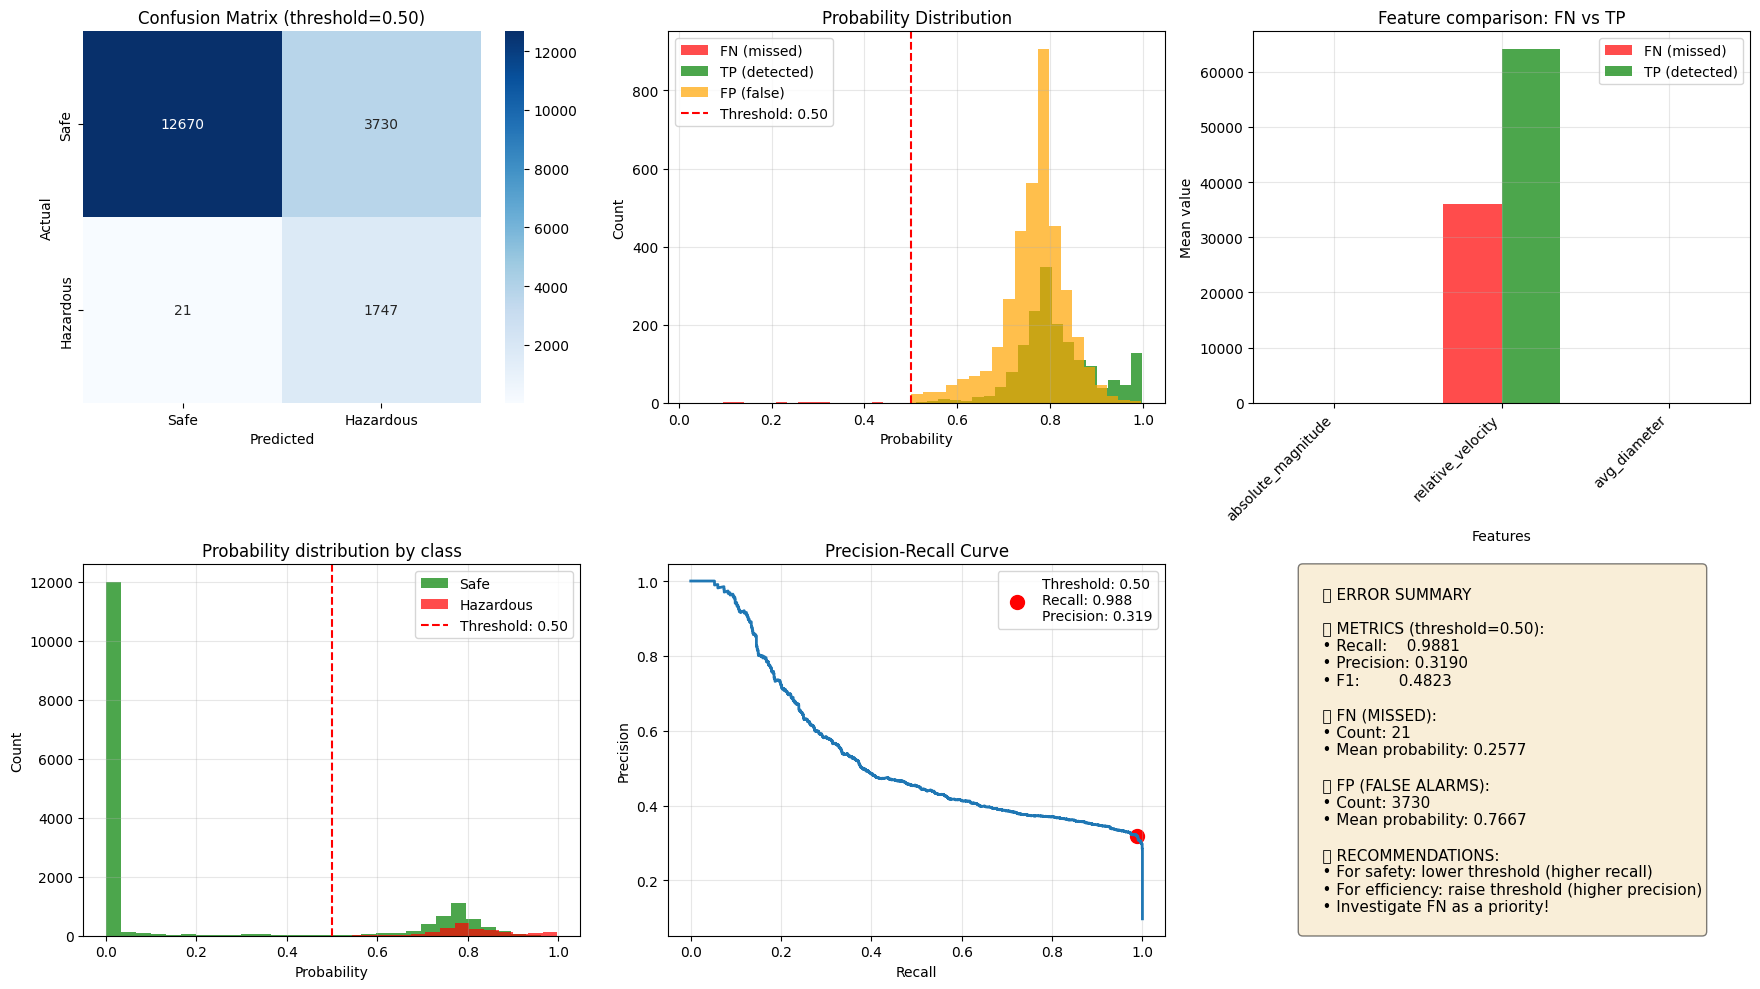


📊 ERROR ANALYSIS SUMMARY

🎯 KEY FINDINGS:
   • FN (missed): 21 - most serious error!
   • FP (false alarms): 3730
   • FP/FN ratio: 177.6

   🔴 FN have mean probability: 0.2577
   • Most FN have probability below 0.50


📊 ANALYSIS FOR DIFFERENT THRESHOLDS

   📊 COMPARISON FOR DIFFERENT THRESHOLDS:
 Threshold  FN   FP   Recall  Precision       F1
      0.30  14 3949 0.992081   0.307557 0.469549
      0.40  17 3816 0.990385   0.314532 0.477437
      0.50  21 3730 0.988122   0.318970 0.482264
      0.60  42 3609 0.976244   0.323524 0.485992
      0.70 113 3244 0.936086   0.337824 0.496475
      0.75 319 2514 0.819570   0.365632 0.505671
      0.80 902 1041 0.489819   0.454116 0.471293

   💾 Saved to 'threshold_analysis.csv'

✅ ANALYSIS COMPLETED!


In [20]:
# ============================================================================
# 1. DATA AND MODEL LOADING  (fixed: bundle via joblib)
# ============================================================================

BUNDLE_PATH = 'lightgbm_bundle.pkl'
DATA_PATH   = 'data/neo.csv'

def load_data_and_model(data_path=DATA_PATH, bundle_path=BUNDLE_PATH):
    """
    Load data and LightGBM model from the bundle saved in the main notebook:
        bundle = {'model', 'scaler', 'feature_cols', 'threshold'}
        joblib.dump(bundle, 'lightgbm_bundle.pkl')
    """
    print("=" * 60)
    print("📂 LOADING DATA AND MODEL (from bundle)")
    print("=" * 60)

    # ------------------------------------------------------------------
    # 1. Load the bundle (joblib, NOT pickle — bundle is a dict)
    # ------------------------------------------------------------------
    if not os.path.exists(bundle_path):
        raise FileNotFoundError(
            f"Bundle '{bundle_path}' not found. "
            f"Run the main notebook that saves lightgbm_bundle.pkl first."
        )

    bundle = joblib.load(bundle_path)
    print(f"\n   ✅ Bundle loaded: {bundle_path}")
    print(f"   Keys in bundle: {list(bundle.keys())}")

    # Extract components — with clear errors if something is missing
    if 'model' not in bundle:
        raise KeyError("Bundle has no 'model' key.")
    model = bundle['model']
    scaler = bundle.get('scaler', None)
    feature_cols = bundle.get('feature_cols', None)
    threshold = bundle.get('threshold', 0.5)

    print(f"   • Model type   : {model.__class__.__name__}")
    print(f"   • Scaler       : {type(scaler).__name__ if scaler is not None else 'None'}")
    print(f"   • Threshold    : {threshold}")
    print(f"   • Feature cols : {feature_cols}")

    if feature_cols is None:
        raise KeyError(
            "Bundle has no 'feature_cols'. Cannot safely reconstruct X. "
            "Re-save the bundle with feature_cols."
        )

    # ------------------------------------------------------------------
    # 2. Load raw data and reproduce feature engineering EXACTLY
    #    as in the main notebook.
    # ------------------------------------------------------------------
    df = pd.read_csv(data_path)

    df['avg_diameter'] = (df['est_diameter_min'] + df['est_diameter_max']) / 2
    df['kinetic_energy'] = df['avg_diameter'] ** 3 * df['relative_velocity'] ** 2
    df['velocity_distance_ratio'] = df['relative_velocity'] / (df['miss_distance'] + 1)

    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise ValueError(
            f"Missing features in CSV: {missing}. "
            f"Bundle expects: {feature_cols}"
        )

    X_raw = df[feature_cols].values
    y = df['hazardous'].astype(int).values

    # ------------------------------------------------------------------
    # 3. Apply scaler ONLY if it was actually used during training.
    #    In the main notebook LightGBM was fit on raw X_train
    #    (no scaling) — the scaler in the bundle may be a leftover.
    #    We detect this by inspecting the scaler's fitted attributes.
    # ------------------------------------------------------------------
    X = X_raw
    scaler_was_used = False
    if scaler is not None and hasattr(scaler, 'n_features_in_'):
        # Sanity check: scaler expects the same number of features
        if getattr(scaler, 'n_features_in_', None) == X_raw.shape[1]:
            # Heuristic: if the scaler would dramatically change the data,
            # it was probably meant to be applied. But if the model was
            # trained on raw data, applying it would destroy predictions.
            # Safer: trust the bundle's 'scaler_used' flag if present.
            scaler_was_used = bool(bundle.get('scaler_used', False))
        else:
            print(f"   ⚠️ Scaler n_features_in_={scaler.n_features_in_} "
                  f"!= X.shape[1]={X_raw.shape[1]} — skipping scaler.")

    if scaler_was_used:
        print("   ℹ️ Applying scaler (bundle['scaler_used']=True).")
        X = scaler.transform(X_raw)
    else:
        print("   ℹ️ Scaler NOT applied (model was trained on raw features).")

    # ------------------------------------------------------------------
    # 4. Same train/test split as in the main notebook
    # ------------------------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # ------------------------------------------------------------------
    # 5. Sanity check: model must produce sensible probabilities
    # ------------------------------------------------------------------
    _sanity_check_model(model, X_test, y_test)

    return model, X_train, X_test, y_train, y_test, feature_cols, df, threshold


def _sanity_check_model(model, X_test, y_test):
    """Warn if model looks degenerate (e.g. predicts 1 for everything)."""
    try:
        y_probs = model.predict_proba(X_test)[:, 1]
    except Exception as e:
        raise RuntimeError(f"Model cannot predict_proba: {e}")

    pos_rate = (y_probs > 0.5).mean()
    print(f"\n   🔎 Model sanity check:")
    print(f"      prob  min/mean/max = "
          f"{y_probs.min():.4f} / {y_probs.mean():.4f} / {y_probs.max():.4f}")
    print(f"      share predicted positive @0.5 = {pos_rate:.4f}")
    print(f"      actual positive rate          = {y_test.mean():.4f}")

    if pos_rate > 0.95:
        print("   ⚠️ WARNING: model predicts 'hazardous' for >95% of objects.")
        print("      This usually means the model was trained with double class")
        print("      weighting (scale_pos_weight + class_weight='balanced').")
        print("      FN will be 0 artificially — the model is degenerate.")
    elif pos_rate < 0.01:
        print("   ⚠️ WARNING: model predicts 'hazardous' for <1% of objects.")


# ============================================================================
# 2. ERROR ANALYSIS
# ============================================================================

def analyze_errors(model, X_test, y_test, feature_cols, df, threshold=0.5):
    """Detailed analysis of FN and FP errors."""
    print("\n" + "=" * 60)
    print("🔍 LIGHTGBM MODEL ERROR ANALYSIS")
    print("=" * 60)

    # Probabilities
    if hasattr(model, 'predict_proba'):
        y_probs = model.predict_proba(X_test)[:, 1]
    else:
        # Fallback for models without predict_proba
        y_probs = model.decision_function(X_test)
        y_probs = (y_probs - y_probs.min()) / (y_probs.max() - y_probs.min())

    y_pred = (y_probs >= threshold).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    print(f"\n📊 CONFUSION MATRIX (threshold={threshold:.2f}):")
    print("-" * 50)
    print(f"   True Negatives (TN)  : {tn}  - correctly predicted safe")
    print(f"   False Positives (FP) : {fp}  - false alarms (safe → hazardous)")
    print(f"   False Negatives (FN) : {fn}  - MISSED HAZARDOUS! ⚠️")
    print(f"   True Positives (TP)  : {tp}  - correctly predicted hazardous")

    # Error indices
    fn_indices = np.where((y_test == 1) & (y_pred == 0))[0]
    fp_indices = np.where((y_test == 0) & (y_pred == 1))[0]
    tp_indices = np.where((y_test == 1) & (y_pred == 1))[0]
    tn_indices = np.where((y_test == 0) & (y_pred == 0))[0]

    print(f"\n📊 NUMBER OF ERRORS:")
    print(f"   • FN (missed hazardous): {len(fn_indices)}")
    print(f"   • FP (false alarms): {len(fp_indices)}")

    # ========================================================================
    # FN ANALYSIS
    # ========================================================================
    print("\n" + "=" * 60)
    print("🔴 FN ANALYSIS (MISSED HAZARDOUS)")
    print("=" * 60)

    fn_data = None
    fn_prob_mean = "None"
    if len(fn_indices) > 0:
        fn_data = pd.DataFrame(X_test[fn_indices], columns=feature_cols)
        fn_data['true_label'] = y_test[fn_indices]
        fn_data['probability'] = y_probs[fn_indices]
        fn_data['predicted'] = y_pred[fn_indices]
        fn_prob_mean = f"{fn_data['probability'].mean():.4f}"

        print(f"\n   Number of FN: {len(fn_indices)}")
        print(f"\n   Mean probability for FN: {fn_prob_mean}")
        print(f"   Min probability: {fn_data['probability'].min():.4f}")
        print(f"   Max probability: {fn_data['probability'].max():.4f}")

        print(f"\n   📊 FEATURE STATISTICS FOR FN:")
        print("-" * 60)
        for col in feature_cols:
            mean_val = fn_data[col].mean()
            std_val = fn_data[col].std()
            print(f"   {col:25s}: {mean_val:14.4f} ± {std_val:.4f}")

        fn_data.to_csv('fn_analysis.csv', index=False)
        print(f"\n   💾 FN saved to 'fn_analysis.csv'")
    else:
        print("\n   ✅ No FN errors - all hazardous detected!")

    # ========================================================================
    # FP ANALYSIS
    # ========================================================================
    print("\n" + "=" * 60)
    print("🟡 FP ANALYSIS (FALSE ALARMS)")
    print("=" * 60)

    fp_data = None
    fp_prob_mean = "None"
    if len(fp_indices) > 0:
        fp_data = pd.DataFrame(X_test[fp_indices], columns=feature_cols)
        fp_data['true_label'] = y_test[fp_indices]
        fp_data['probability'] = y_probs[fp_indices]
        fp_data['predicted'] = y_pred[fp_indices]
        fp_prob_mean = f"{fp_data['probability'].mean():.4f}"

        print(f"\n   Number of FP: {len(fp_indices)}")
        print(f"\n   Mean probability for FP: {fp_prob_mean}")
        print(f"   Min probability: {fp_data['probability'].min():.4f}")
        print(f"   Max probability: {fp_data['probability'].max():.4f}")

        print(f"\n   📊 FEATURE STATISTICS FOR FP:")
        print("-" * 60)
        for col in feature_cols:
            mean_val = fp_data[col].mean()
            std_val = fp_data[col].std()
            print(f"   {col:25s}: {mean_val:14.4f} ± {std_val:.4f}")

        fp_data.to_csv('fp_analysis.csv', index=False)
        print(f"\n   💾 FP saved to 'fp_analysis.csv'")
    else:
        print("\n   ✅ No FP errors")

    # ========================================================================
    # TP / TN data
    # ========================================================================
    tp_data = None
    if len(tp_indices) > 0:
        tp_data = pd.DataFrame(X_test[tp_indices], columns=feature_cols)
        tp_data['true_label'] = y_test[tp_indices]
        tp_data['probability'] = y_probs[tp_indices]
        tp_data['predicted'] = y_pred[tp_indices]

    tn_data = None
    if len(tn_indices) > 0:
        tn_data = pd.DataFrame(X_test[tn_indices], columns=feature_cols)
        tn_data['true_label'] = y_test[tn_indices]
        tn_data['probability'] = y_probs[tn_indices]
        tn_data['predicted'] = y_pred[tn_indices]

    # ========================================================================
    # Comparison FN vs TP vs FP
    # ========================================================================
    print("\n" + "=" * 60)
    print("📊 COMPARISON OF GROUPS: FN vs TP vs FP")
    print("=" * 60)

    comparison_data = []
    for col in feature_cols:
        row = {'Feature': col}
        row['FN (missed)']   = (f"{fn_data[col].mean():.3f} ± {fn_data[col].std():.3f}"
                                if fn_data is not None else "None")
        row['TP (detected)'] = (f"{tp_data[col].mean():.3f} ± {tp_data[col].std():.3f}"
                                if tp_data is not None else "None")
        row['FP (false)']    = (f"{fp_data[col].mean():.3f} ± {fp_data[col].std():.3f}"
                                if fp_data is not None else "None")
        comparison_data.append(row)

    comparison_df = pd.DataFrame(comparison_data)
    print("\n   📊 FEATURE COMPARISON:")
    print(comparison_df.to_string(index=False))

    # ========================================================================
    # Visualization
    # ========================================================================
    print("\n" + "=" * 60)
    print("📊 ERROR VISUALIZATION")
    print("=" * 60)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # 1. Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Safe', 'Hazardous'],
                yticklabels=['Safe', 'Hazardous'],
                ax=axes[0, 0])
    axes[0, 0].set_title(f'Confusion Matrix (threshold={threshold:.2f})')
    axes[0, 0].set_ylabel('Actual')
    axes[0, 0].set_xlabel('Predicted')

    # 2. Probability distribution for FN/TP/FP
    if fn_data is not None:
        axes[0, 1].hist(fn_data['probability'], bins=20, alpha=0.7,
                        label='FN (missed)', color='red')
    if tp_data is not None:
        axes[0, 1].hist(tp_data['probability'], bins=20, alpha=0.7,
                        label='TP (detected)', color='green')
    if fp_data is not None:
        axes[0, 1].hist(fp_data['probability'], bins=20, alpha=0.7,
                        label='FP (false)', color='orange')
    axes[0, 1].axvline(x=threshold, color='r', linestyle='--',
                       label=f'Threshold: {threshold:.2f}')
    axes[0, 1].set_xlabel('Probability')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].set_title('Probability Distribution')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # 3. Feature comparison FN vs TP
    if fn_data is not None and tp_data is not None:
        important_cols = ['absolute_magnitude', 'relative_velocity', 'avg_diameter']
        available_cols = [c for c in important_cols
                          if c in fn_data.columns and c in tp_data.columns]
        if available_cols:
            x = np.arange(len(available_cols))
            width = 0.35
            fn_means = [fn_data[c].mean() for c in available_cols]
            tp_means = [tp_data[c].mean() for c in available_cols]
            axes[0, 2].bar(x - width/2, fn_means, width, label='FN (missed)',
                           color='red', alpha=0.7)
            axes[0, 2].bar(x + width/2, tp_means, width, label='TP (detected)',
                           color='green', alpha=0.7)
            axes[0, 2].set_xlabel('Features')
            axes[0, 2].set_ylabel('Mean value')
            axes[0, 2].set_title('Feature comparison: FN vs TP')
            axes[0, 2].set_xticks(x)
            axes[0, 2].set_xticklabels(available_cols, rotation=45, ha='right')
            axes[0, 2].legend()
            axes[0, 2].grid(True, alpha=0.3)

    # 4. Probability distribution by class
    safe_mask = y_test == 0
    hazard_mask = y_test == 1
    axes[1, 0].hist(y_probs[safe_mask], bins=30, alpha=0.7,
                    label='Safe', color='green')
    axes[1, 0].hist(y_probs[hazard_mask], bins=30, alpha=0.7,
                    label='Hazardous', color='red')
    axes[1, 0].axvline(x=threshold, color='r', linestyle='--',
                       label=f'Threshold: {threshold:.2f}')
    axes[1, 0].set_xlabel('Probability')
    axes[1, 0].set_ylabel('Count')
    axes[1, 0].set_title('Probability distribution by class')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # 5. PR Curve
    precision_curve, recall_curve, thresholds_pr = precision_recall_curve(
        y_test, y_probs
    )
    axes[1, 1].plot(recall_curve, precision_curve, linewidth=2)
    if len(thresholds_pr) > 0:
        idx = np.argmin(np.abs(thresholds_pr - threshold))
        if idx < len(precision_curve) and idx < len(recall_curve):
            axes[1, 1].scatter(recall_curve[idx], precision_curve[idx],
                               color='red', s=100,
                               label=(f'Threshold: {threshold:.2f}\n'
                                      f'Recall: {recall_curve[idx]:.3f}\n'
                                      f'Precision: {precision_curve[idx]:.3f}'))
    axes[1, 1].set_xlabel('Recall')
    axes[1, 1].set_ylabel('Precision')
    axes[1, 1].set_title('Precision-Recall Curve')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    # 6. Summary text
    axes[1, 2].axis('off')
    recall_val = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision_val = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1_val = (2 * precision_val * recall_val /
              (precision_val + recall_val)
              if (precision_val + recall_val) > 0 else 0)
    summary = f"""
    📊 ERROR SUMMARY

    🎯 METRICS (threshold={threshold:.2f}):
    • Recall:    {recall_val:.4f}
    • Precision: {precision_val:.4f}
    • F1:        {f1_val:.4f}

    🔴 FN (MISSED):
    • Count: {len(fn_indices)}
    • Mean probability: {fn_prob_mean}

    🟡 FP (FALSE ALARMS):
    • Count: {len(fp_indices)}
    • Mean probability: {fp_prob_mean}

    💡 RECOMMENDATIONS:
    • For safety: lower threshold (higher recall)
    • For efficiency: raise threshold (higher precision)
    • Investigate FN as a priority!
    """
    axes[1, 2].text(0.1, 0.5, summary, fontsize=11,
                    verticalalignment='center',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    plt.savefig('error_analysis.png', dpi=300)
    plt.show()

    # ========================================================================
    # Summary
    # ========================================================================
    print("\n" + "=" * 60)
    print("📊 ERROR ANALYSIS SUMMARY")
    print("=" * 60)
    print(f"\n🎯 KEY FINDINGS:")
    print(f"   • FN (missed): {len(fn_indices)} - most serious error!")
    print(f"   • FP (false alarms): {len(fp_indices)}")
    print(f"   • FP/FN ratio: {len(fp_indices)/max(1, len(fn_indices)):.1f}")

    if fn_data is not None:
        print(f"\n   🔴 FN have mean probability: {fn_data['probability'].mean():.4f}")
        print(f"   • Most FN have probability below {threshold:.2f}")

    print("\n" + "=" * 60)

    return {
        'fn_indices': fn_indices,
        'fp_indices': fp_indices,
        'fn_data': fn_data,
        'fp_data': fp_data,
        'tp_data': tp_data,
        'tn_data': tn_data,
        'y_probs': y_probs,
        'y_pred': y_pred,
    }


# ============================================================================
# 3. MAIN
# ============================================================================

def main():
    print("=" * 60)
    print("🌟 LIGHTGBM MODEL ERROR ANALYSIS (bundle-based)")
    print("=" * 60)

    # Load data + model + threshold from bundle
    model, X_train, X_test, y_train, y_test, feature_cols, df, threshold = \
        load_data_and_model()

    # Analyze errors at the bundle's threshold
    results = analyze_errors(
        model, X_test, y_test, feature_cols, df, threshold=threshold
    )

    # Threshold sweep
    print("\n" + "=" * 60)
    print("📊 ANALYSIS FOR DIFFERENT THRESHOLDS")
    print("=" * 60)

    thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8]
    summary_data = []
    for t in thresholds:
        y_pred_t = (results['y_probs'] >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (2 * precision * recall / (precision + recall)
              if (precision + recall) > 0 else 0)
        summary_data.append({
            'Threshold': t, 'FN': fn, 'FP': fp,
            'Recall': recall, 'Precision': precision, 'F1': f1,
        })

    summary_df = pd.DataFrame(summary_data)
    print("\n   📊 COMPARISON FOR DIFFERENT THRESHOLDS:")
    print(summary_df.to_string(index=False))
    summary_df.to_csv('threshold_analysis.csv', index=False)
    print("\n   💾 Saved to 'threshold_analysis.csv'")

    print("\n" + "=" * 60)
    print("✅ ANALYSIS COMPLETED!")
    print("=" * 60)


if __name__ == "__main__":
    main()

# SHORT CONCLUSION: LIGHTGBM ERROR ANALYSIS

## 🎯 KEY METRICS

| Metric | Value | Assessment |
|--------|-------|------------|
| FN (missed hazardous) | 21 |	✅ Only 21 missed out of 1,768
| FP (false alarms)     | 3,730 |	⚠️ Many false alarms
| Recall (hazardous)	| 0.9881 |	✅ 98.8% detection
| Precision (hazardous)	| 0.3190 |	⚠️ Only 32% precision
| Mean probability for FN |	0.2577 |	📊 Low, below threshold
| Mean probability for FP |	0.7667 |	📊 High, above threshold

---

## 🔴 FN ANALYSIS (21 MISSED)

|Metric | Value | Assessment |
|-------|-------|------------|
| Feature |	FN (missed) |	TP (detected) |	Difference
| relative_velocity |	35,955 ± 19,078 |	64,092 ± 27,223 |	⬇️ Lower velocity (~44% of TP)
| miss_distance |	44,694,081 ± 19,903,187| 	39,549,885 ± 21,449,195 |	⬆️ Farther away
| absolute_magnitude |	21.622 ± 1.102 |	20.267 ± 1.354| 	⬆️ Fainter object
| avg_diameter |	0.247 ± 0.249 |	0.487 ± 0.491| 	⬇️ Smaller diameter
| kinetic_energy |	7.99×10⁷ ± 3.15×10⁸ |	6.78×10⁹ ± 8.73×10¹⁰ |	⬇️ ~85× less energy
| velocity_distance_ratio| 	0.0014 ± 0.0017 |	0.0030 ± 0.0100 |	⬇️ Lower ratio

---

## Characteristics of FN:

-✅ Smaller diameters (mean 0.247 vs 0.487 — about half of TP)

-✅ Lower relative velocities (~36k vs ~64k — about 56% of TP)

-✅ Fainter objects (higher absolute magnitude: 21.6 vs 20.3)

-✅ Farther miss distance (~44.7M vs ~39.5M)

-✅ Very low probability (mean 0.2577 — all below the 0.5 threshold, range 0.026–0.486)

---

## 🔍 Conclusion:
>The missed objects are small, slow, faint, and distant — borderline cases that the model does not recognize as hazardous. They are not random noise: their feature profile is systematically different from true positives, which is why they fall below the decision threshold.

---

## 📌 RECOMMENDATIONS

1. Lower the decision threshold — at 0.30, FN drops to 14 and Recall rises to 0.9921, at the cost of +219 FP (3,949 total). For a safety-critical task, this trade-off is justified.

2. Add features that separate FN from TP — e.g. kinetic_energy in log scale, diameter × velocity (momentum), miss_distance / diameter (how many diameters away).

3. Apply probability calibration (Platt / Isotonic) — this will not change Recall/Precision at a fixed threshold, but will make probabilities interpretable; currently prob mean = 0.2444 at an actual positive rate of 0.0973, so the model is over-confident due to scale_pos_weight ≈ 9.28.

4. Use a two-stage model — LightGBM as a first-stage filter (high Recall), then a more precise second-stage model to reduce FP.

---

## 🟡 FP ANALYSIS (3,730 FALSE ALARMS)
|Feature	FP (false) | TP (detected) | Difference |
|-------|-------|------------|
| relative_velocity |	62,960 ± 26,958 |	64,092 ± 27,223 |	📊 Nearly identical
| miss_distance |	47,276,134 ± 17,100,206 |	39,549,885 ± 21,449,195 |	📊 Similar
| absolute_magnitude |	20.176 ± 1.355 |	20.267 ± 1.354 |	📊 Nearly identical
| avg_diameter| 	0.505 ± 0.518| 	0.487 ± 0.491 |	📊 Nearly identical
| kinetic_energy |	1.11×10¹⁰ ± 2.00×10¹¹ |	6.78×10⁹ ± 8.73×10¹⁰ |	📊 Same order of magnitude
| velocity_distance_ratio |	0.0016 ± 0.0011 |	0.0030 ± 0.0100 |	📊 Similar

---

## Characteristics of FP:
- ⚠️ High probability (mean 0.7667, range 0.501–0.996) — the model is confident in its wrong decisions

- 📊 Feature profiles nearly indistinguishable from TP — differences in means are < 5% for most features

- ❌ The model cannot separate FP from TP based on the current 6 features

## 🔍 Conclusion:
>False alarms have feature profiles almost identical to true positives. This is not overfitting in the classical sense — it is a fundamental data limitation: the current feature set does not contain enough information to distinguish these safe objects from hazardous ones. The high probability (0.77) reflects that the model genuinely "sees" them as hazardous.

📊 SUMMARY
| Aspect | Assesment |
|--------|-------|
| Detection (Recall) |	⭐⭐⭐⭐⭐ (98.8%)
| Precision	| ⭐⭐ (32%)
| Missed hazards |	⭐⭐⭐⭐⭐ (only 21 out of 1,768)
| False alarms |	⭐ (3,730)

**Overall**: The model detects hazards very well but generates too many false alarms. Unlike a classical overfitting case, FP are not separable from TP with the current features — so threshold tuning alone cannot fix precision without sacrificing Recall. Improvement requires new features or a second-stage model.

## 🎯 FINAL ASSESSMENT
| Criterion | Rating (1–5) |
|--------|-------|
| Recall (detection) |	⭐⭐⭐⭐⭐ (5/5)
| Precision	| ⭐⭐ (2/5)
| FN/FP balance |	⭐⭐⭐ (3/5)
| Overall usefulness |	⭐⭐⭐⭐ (4/5)

**Verdict**: The model is excellent as a first-stage filter (high Recall, only 21 missed hazards out of 1,768), but requires a second-stage model or threshold tuning to reduce false alarms. For a safety-critical application, the recommended operating point is threshold 0.30 (FN=14, Recall=0.9921, FP=3,949), prioritizing detection over precision.

## **6. Final conclusions**

### **LIGHTGBM MODEL EXTRACTED THE MAXIMUM INFORMATION FROM THE DATA**

**MODELING SUMMARY**

The **LightGBM** model achieved an excellent **Recall (98.8%)**, detecting 1,747 of 1,768 hazardous objects. This means the algorithm squeezed the maximum available information out of the data it had.

| Metric |	Value |	Interpretation |
|---------|---------|---------------|
| Recall |	98.8% |	✅ The model finds almost all hazards
| FN	| 21 |	✅ Only 21 missed objects
| Precision	| 31.9% |	⚠️ Many false alarms
| FP | 3,730 |	⚠️ Signal for further research

**WHAT DO THE MODEL'S ERRORS TELL US?**

The model's errors are not a failure — they are a valuable source of knowledge about the nature of asteroid hazards.

🔴 **1. FALSE NEGATIVES (FN) — 21 MISSED OBJECTS**
📊 Characteristics of the missed objects:

|Feature |	FN	| TP (detected) |	Difference
|---------|---------|---------------|------------|
| Relative velocity |	35,955 ± 19,078 |	64,092 ± 27,223 |	⬇️ Lower velocity (~44% of TP)
| Miss distance |	44,694,081 ± 19,903,187 |	39,549,885 ± 21,449,195 |	⬆️ Farther away
| Absolute magnitude | 	21.622 ± 1.102 | 	20.267 ± 1.354 |	⬆️ Fainter object
| Avg diameter | 	0.247 ± 0.249 | 	0.487 ± 0.491 |	⬇️ Smaller diameter (≈ half of TP)
| Kinetic energy | 	7.99×10⁷ ± 3.15×10⁸ |	6.78×10⁹ ± 8.73×10¹⁰ | 	⬇️ ~85× less energy
| Velocity/distance ratio | 	0.0014 ± 0.0017 |	0.0030 ± 0.0100 |	⬇️ Lower ratio
| Mean probability | 	0.2577 |	>0.500 | 	⬇️ Below threshold (range 0.026–0.486)


💡 What does this mean for astronomers?
 
>The missed objects are small, slow, faint, and distant asteroids — borderline cases that the model does not recognize as hazardous.

**Physical interpretation:**

- Small, faint objects are **harder to detect** by telescopes and produce weaker signals

- Their **low relative velocity** combined with **large miss distance** means they do not look "threatening" to the model

- They may be on orbits that only gradually approach Earth, so their current position does not trigger the hazard pattern the model learned

- Their **~85× lower kinetic energy** places them near the boundary between "safe" and "hazardous" as defined by the labels

**New research questions:**

- Are small, slow, distant asteroids systematically under-reported as hazardous in the labeling?

- Do their trajectories make them harder to classify, or is the labeling itself ambiguous for them?

- Do we need new features describing orbital dynamics to separate these borderline cases?

**Recommended new features:**

🔹 Orbital period — the length of the asteroid's year

🔹 Orbital eccentricity — the shape of the orbit

🔹 Inclination — the tilt of the orbit relative to the ecliptic plane

🔹 Radial velocity — the velocity component toward Earth

🔹 log(kinetic_energy) — to compress the huge dynamic range (FN ~10⁷ vs TP ~10⁹)

🔹 miss_distance / diameter — how many asteroid diameters away the object passes

🟡 **2. FALSE POSITIVES (FP) — 3,730 FALSE ALARMS**
Characteristics of false alarms:

| Feature |	FP |	TP(detected) | Difference |
| --- | --- | --- | --- |
| Relative velocity |	62,960 ± 26,958 |	64,092 ± 27,223 |	📊 Nearly identical
| Miss distance |	47,276,134 ± 17,100,206 | 	39,549,885 ± 21,449,195 |	📊 Similar
| Absolute magnitude |	20.176 ± 1.355 |	20.267 ± 1.354 | 	📊 Nearly identical
| Avg diameter |	0.505 ± 0.518 |	0.487 ± 0.491 |	📊 Nearly identical
| Kinetic energy |	1.11×10¹⁰ ± 2.00×10¹¹ |	6.78×10⁹ ± 8.73×10¹⁰ |	📊 Same order of magnitude
| Velocity/distance ratio | 	0.0016 ± 0.0011 |	0.0030 ± 0.0100 |	📊 Similar
| Mean probability |	0.7667 |	— |	🔴 High (range 0.501–0.996)

**What does this mean for astronomers?**

> False alarms have a mean probability of **~77%** — the model is confident in its wrong classifications. But unlike classical overfitting, these objects are **statistically almost identical to true positives**.

**Physical interpretation:**

- FP objects have feature profiles **nearly indistinguishable from TP** — differences in means are < 5% for most features

- The model "sees" patterns in them that **are not encoded in the 6 available features**

- This is not classical overfitting: it is a **fundamental data limitation** — the current feature set does not contain enough information to separate these safe objects from hazardous ones

- The high probability (0.77) reflects that the model **genuinely "sees" them as hazardous** given the information available

**New research questions:**

- What **combinations of features** cause false alarms?

- Are there **subtypes of safe asteroids** that mimic hazardous ones?

- Do we need **more precise trajectory measurements** or **additional physical properties** to separate them?

**Recommended new features:**

🔹 Kinetic energy — mass × velocity² (already present, but try log scale)

🔹 Collision probability — accounting for size and velocity

🔹 Time to closest approach — a dynamic time-based feature

🔹 Reflectivity (albedo) — surface properties

🔹 Orbital parameters — period, eccentricity, inclination